In [1]:
# Write your imports here
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import ttest_ind

# Data Visualization. Exploratory Data Analysis Exercise
## Visualizing and exploring data. The data mining process

You should already know the `MyAnimeList` dataset, located [here](https://www.kaggle.com/datasets/andreuvallhernndez/myanimelist). You've already looked at it, cleaned a significant part of it, and you should now be ready to explore some interesting things about it.

Once again, feel free to follow the problem descriptions as closely (or as loosely) as you want.

**Don't forget reproducibility!** I suggest you have a look at a tool called [dvc](https://dvc.org/), short for _data version control_.

### Problem 1. Load the data
You should ideally load the cleaned version you saved last time. But you may start from the original dataset as well, or from an intermediate version.

Don't hesitate to load multiple versions, e.g., with different features, and compare results across them to assess hwo your transformations affect the results you get. In fact, it's a common thing we do.

In [2]:
data_dir = Path(
    r"D:\Data Science\01. Exercise Working with Data\cleaned_data"
)

anime = pd.read_csv(data_dir / "anime_cleaned.csv")
manga = pd.read_csv(data_dir / "manga_cleaned.csv")

print("Anime:", anime.shape)
print("Manga:", manga.shape)

Anime: (24985, 62)
Manga: (64833, 49)


In [3]:
columns = ["type", "score", "scored_by", "members", "real_start_date"]

print("Anime:")
print(anime[columns].dtypes)

print("\nManga:")
print(manga[columns].dtypes)

Anime:
type                   str
score              float64
scored_by            int64
members              int64
real_start_date        str
dtype: object

Manga:
type                   str
score              float64
scored_by            int64
members              int64
real_start_date        str
dtype: object


In [4]:
for df in [anime, manga]:
    df["real_start_date"] = pd.to_datetime(
        df["real_start_date"],
        errors="coerce"
    )

    df["release_year"] = df["real_start_date"].dt.year

print("Anime:")
print(anime[["real_start_date", "release_year"]].head())

print("\nManga:")
print(manga[["real_start_date", "release_year"]].head())

Anime:
  real_start_date  release_year
0      2009-04-05        2009.0
1      2011-10-02        2011.0
2      2019-04-29        2019.0
3      2011-04-06        2011.0
4      2016-09-17        2016.0

Manga:
  real_start_date  release_year
0      1989-08-25        1989.0
1      1997-07-22        1997.0
2      2004-01-19        2004.0
3      2007-03-15        2007.0
4      2001-07-12        2001.0


In [5]:
for df in [anime, manga]:
    df["release_year"] = df["release_year"].astype("Int64")

### Problem 2. Get a sense of scale
What's the global behavior of both datasets? Explore and visualize how many works there are, and how they're distributed across different key categories (number of episodes, audience, release year, etc.). Try not to bother with the "list" columns now.

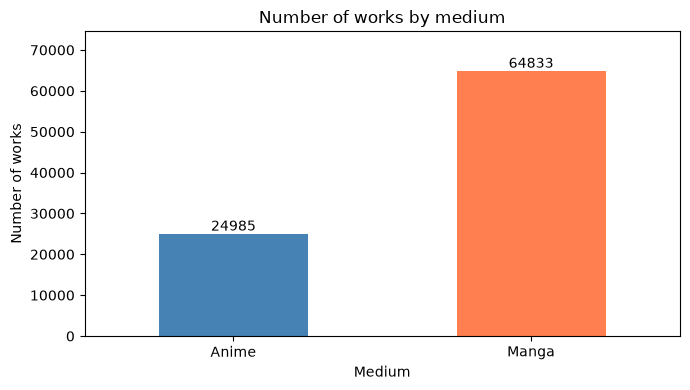

In [6]:
work_counts = pd.Series({
    "Anime": len(anime),
    "Manga": len(manga)
})

ax = work_counts.plot.bar(
    figsize=(7, 4),
    color=["steelblue", "coral"],
    rot=0
)

ax.set_title("Number of works by medium")
ax.set_xlabel("Medium")
ax.set_ylabel("Number of works")
ax.bar_label(ax.containers[0], fmt="%.0f")
ax.margins(y=0.15)

plt.tight_layout()
plt.show()

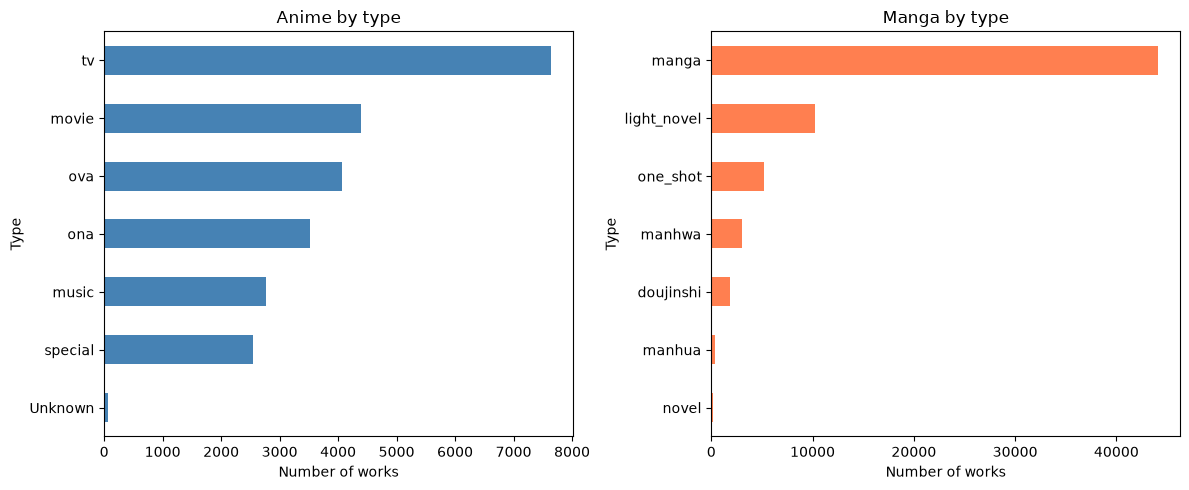

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for df, ax, title, color in [
    (anime, axes[0], "Anime by type", "steelblue"),
    (manga, axes[1], "Manga by type", "coral")
]:
    counts = df["type"].fillna("Unknown").value_counts()
    counts.sort_values().plot.barh(ax=ax, color=color)

    ax.set_title(title)
    ax.set_xlabel("Number of works")
    ax.set_ylabel("Type")

plt.tight_layout()
plt.show()

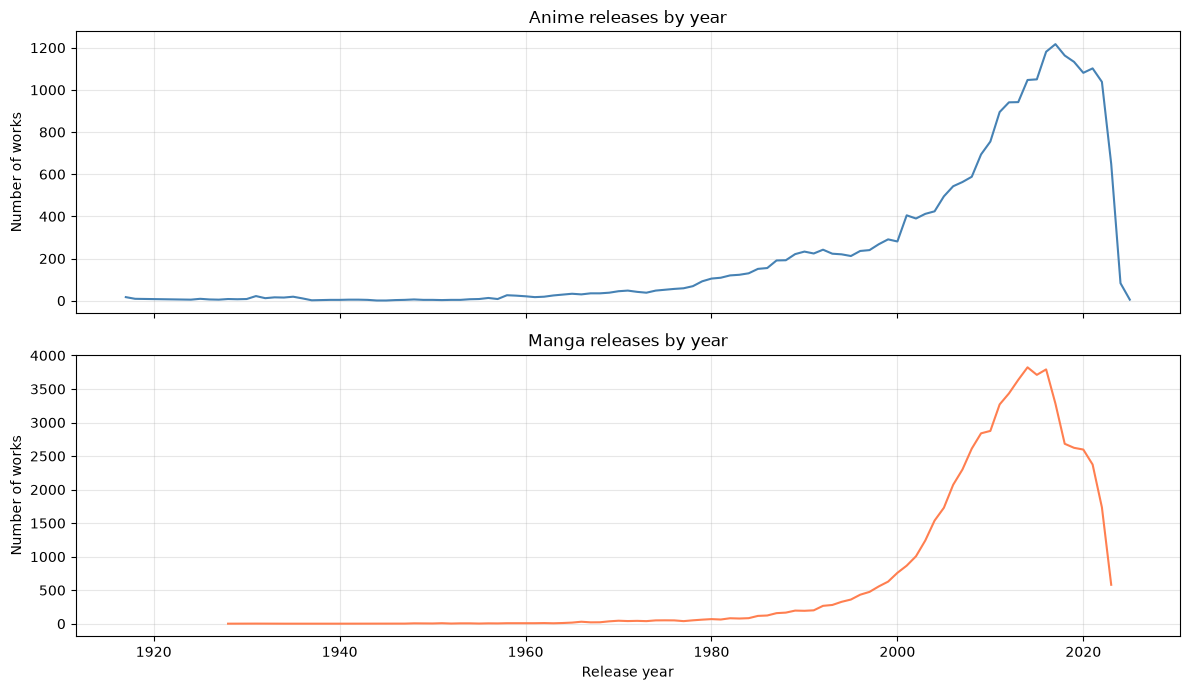

In [8]:
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)

for df, ax, title, color in [
    (anime, axes[0], "Anime releases by year", "steelblue"),
    (manga, axes[1], "Manga releases by year", "coral")
]:
    yearly_counts = (
        df["release_year"]
        .dropna()
        .value_counts()
        .sort_index()
    )

    ax.plot(yearly_counts.index, yearly_counts.values, color=color)
    ax.set_title(title)
    ax.set_ylabel("Number of works")
    ax.grid(alpha=0.3)

axes[1].set_xlabel("Release year")

plt.tight_layout()
plt.show()

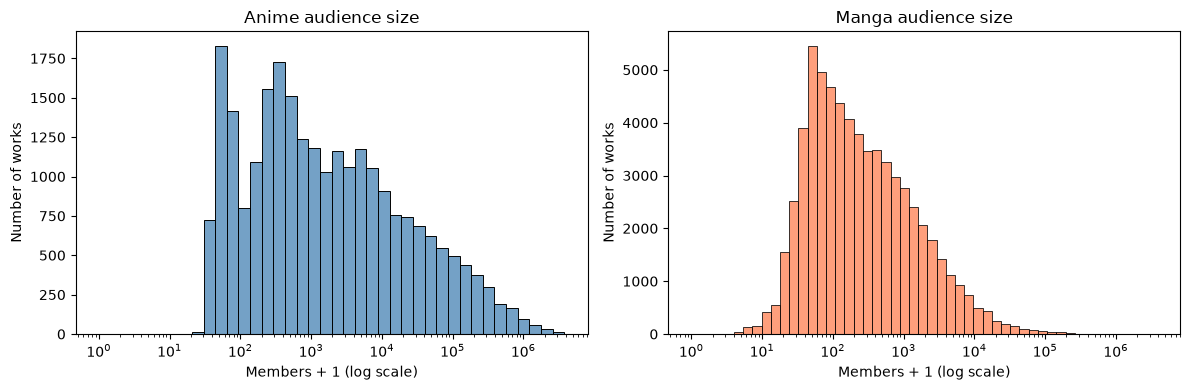

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharex=True)

for df, ax, title, color in [
    (anime, axes[0], "Anime audience size", "steelblue"),
    (manga, axes[1], "Manga audience size", "coral")
]:
    members = df["members"].dropna()

    # +1 allows zero values on a logarithmic scale
    sns.histplot(
        x=members + 1,
        bins=40,
        log_scale=True,
        ax=ax,
        color=color
    )

    ax.set_title(title)
    ax.set_xlabel("Members + 1 (log scale)")
    ax.set_ylabel("Number of works")

plt.tight_layout()
plt.show()

count    24438.000000
mean        14.877486
std         48.447625
min          1.000000
25%          1.000000
50%          2.000000
75%         13.000000
max       3057.000000
Name: episodes, dtype: float64


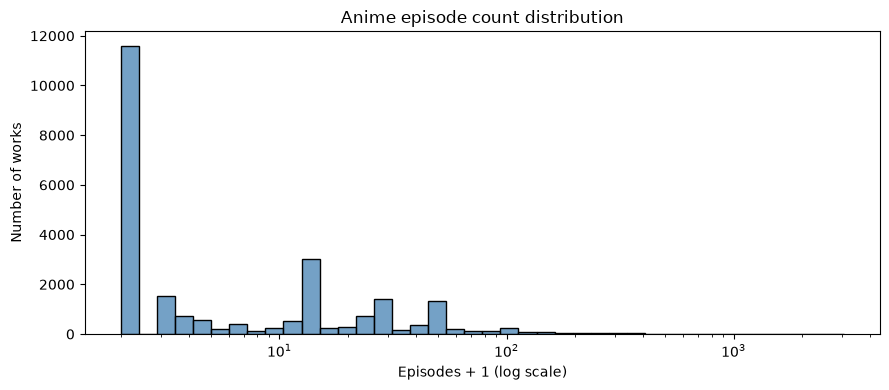

In [10]:
episodes = anime["episodes"].dropna()

print(episodes.describe())

fig, ax = plt.subplots(figsize=(9, 4))

sns.histplot(
    x=episodes + 1,
    bins=40,
    log_scale=True,
    color="steelblue",
    ax=ax
)

ax.set_title("Anime episode count distribution")
ax.set_xlabel("Episodes + 1 (log scale)")
ax.set_ylabel("Number of works")

plt.tight_layout()
plt.show()

### Problem 2 — Summary

- The datasets contain 24,985 anime and 64,833 manga works.
- TV is the most common anime type; manga is the most common
  type in the manga dataset.
- Recorded releases increase substantially after 2000.
  The decline near the dataset boundary requires further
  investigation and may reflect incomplete coverage.
- Audience sizes vary widely, with relatively few works
  reaching very large membership counts.
- Among anime with known episode counts, the median is 2
  and the mean is approximately 14.88 episodes.
  75% have at most 13 episodes, while the maximum is 3,057.
- Episode counts are missing for 547 anime.
- These observations describe this dataset and its coverage.

### Problem 3. Scores
You should already know there are many viewpoints to what we call "score". How are scores distributed and what can we learn about them?

Try to come up with a good, explainable, scoring method. There's no universal formula for this, but at the very least we should look at the number of people giving a score. A "4.5" average can mean different things if 10 or 10 000 people have voted.


Anime — score statistics
count    16050.000000
mean         6.418470
std          0.899305
min          1.850000
25%          5.800000
50%          6.420000
75%          7.070000
max          9.100000
Name: score, dtype: float64
Missing scores: 8935

Manga — score statistics
count    24636.000000
mean         6.945179
std          0.520170
min          2.440000
25%          6.620000
50%          6.910000
75%          7.250000
max          9.470000
Name: score, dtype: float64
Missing scores: 40197


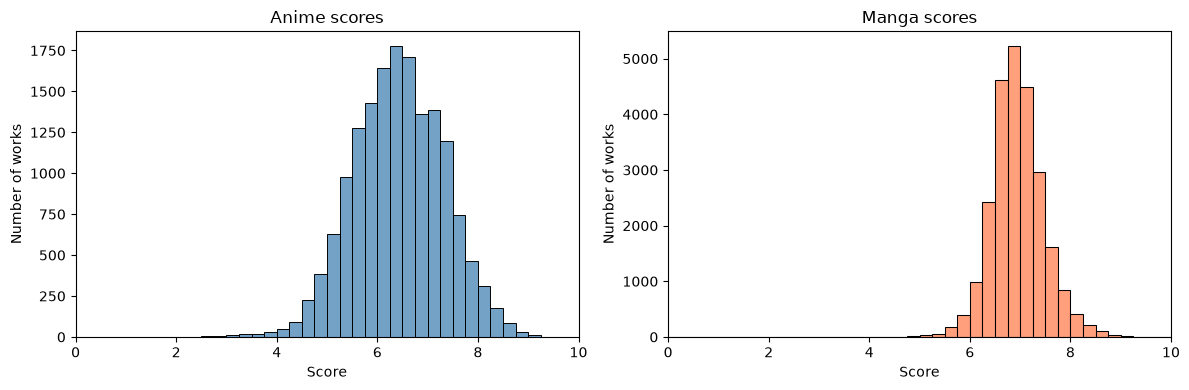

In [11]:
for name, df in [("Anime", anime), ("Manga", manga)]:
    print(f"\n{name} — score statistics")
    print(df["score"].describe())
    print("Missing scores:", df["score"].isna().sum())

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharex=True)

for df, ax, title, color in [
    (anime, axes[0], "Anime scores", "steelblue"),
    (manga, axes[1], "Manga scores", "coral")
]:
    sns.histplot(
        x=df["score"].dropna(),
        bins=[i / 4 for i in range(41)],
        color=color,
        ax=ax
    )

    ax.set_title(title)
    ax.set_xlabel("Score")
    ax.set_ylabel("Number of works")
    ax.set_xlim(0, 10)

plt.tight_layout()
plt.show()

In [12]:
m = 1000

for name, df in [("Anime", anime), ("Manga", manga)]:
    valid = df["score"].notna() & (df["scored_by"] > 0)

    C = df.loc[valid, "score"].mean()
    R = df.loc[valid, "score"]
    v = df.loc[valid, "scored_by"]

    df["weighted_score"] = float("nan")
    df.loc[valid, "weighted_score"] = (
        (v * R + m * C) / (v + m)
    )

    print(f"\n{name}: baseline = {C:.3f}, m = {m}")

    display(
        df.loc[
            valid,
            ["title", "score", "scored_by", "weighted_score"]
        ]
        .sort_values("weighted_score", ascending=False)
        .head(10)
        .round(3)
    )


Anime: baseline = 6.418, m = 1000


,title,score,scored_by,weighted_score
0,Fullmetal Alchemist: Brotherhood,9.10,2037075,9.099
3,Steins;Gate,9.07,1348232,9.068
103,Gintama°,9.06,240466,9.049
114,Bleach: Sennen Kessen-hen,9.06,228906,9.049
2,Shingeki no Kyojin Season 3 Part 2,9.05,1491491,9.048
1,Hunter x Hunter (2011),9.04,1671587,9.038
38,Kaguya-sama wa Kokurasetai: Ultra Romantic,9.04,466692,9.034
117,Gintama',9.04,228236,9.029
187,Shingeki no Kyojin: The Final Season - Kankets...,9.04,170844,9.025
201,Gintama': Enchousen,9.03,159081,9.014



Manga: baseline = 6.945, m = 1000


,title,score,scored_by,weighted_score
0,Berserk,9.47,319696,9.462
2,JoJo no Kimyou na Bouken Part 7: Steel Ball Run,9.30,151433,9.285
5,Vagabond,9.24,129688,9.222
1,One Piece,9.22,355375,9.214
9,Monster,9.15,90296,9.126
16,Slam Dunk,9.08,70877,9.050
6,Vinland Saga,9.05,119797,9.033
4,Fullmetal Alchemist,9.03,153151,9.016
3,Oyasumi Punpun,9.02,168459,9.008
18,Grand Blue,9.03,63438,8.998


In [13]:
for name, df in [("Anime", anime), ("Manga", manga)]:
    few_votes = df[
        df["weighted_score"].notna()
        & (df["scored_by"] < 1000)
    ]

    print(f"\n{name} — highest scores with fewer than 1000 votes")

    display(
        few_votes[
            ["title", "score", "scored_by", "weighted_score"]
        ]
        .sort_values("score", ascending=False)
        .head(10)
        .round(3)
    )


Anime — highest scores with fewer than 1000 votes


,title,score,scored_by,weighted_score
5030,Shen Yin Wangzuo 2nd Season,7.90,814,7.083
5417,Seishun Buta Yarou wa Odekake Sister no Yume w...,7.71,731,6.964
5811,Kaibutsu,7.61,619,6.874
6745,Blue Giant,7.59,322,6.704
5462,Sasaki to Miyano Movie: Sotsugyou-hen,7.58,797,6.934
5652,Modern Love Tokyo: Kare ga Kanaderu Futari no ...,7.55,741,6.900
5335,Yoku,7.54,908,6.952
5437,Xingchen Bian: Po Tian Mi Ju,7.54,860,6.937
6194,Mitsume ga Tooru,7.53,536,6.806
5691,Kiratto Pri☆chan Season 2,7.53,741,6.892



Manga — highest scores with fewer than 1000 votes


,title,score,scored_by,weighted_score
3669,Fata Morgana no Yakata: Anata no Genten ni Ita...,8.64,595,7.577
3107,Souyaku Toaru Majutsu no Index,8.54,720,7.613
2445,Veil,8.51,943,7.705
2381,Umineko no Naku Koro ni Chiru,8.45,977,7.689
3239,Violet Evergarden Gaiden,8.32,703,7.513
2542,After School Lessons for Unripe Apples,8.31,932,7.604
2937,"Natsu e no Tunnel, Sayonara no Deguchi",8.29,797,7.542
2854,Kusuriya no Hitorigoto,8.29,824,7.553
2959,"Mata, Onaji Yume wo Miteita",8.27,793,7.531
3642,Kyoukaisenjou no Horizon,8.23,628,7.441


In [14]:
anime_scores = anime["score"].dropna()
manga_scores = manga["score"].dropna()

result = ttest_ind(
    anime_scores,
    manga_scores,
    equal_var=False
)

print(f"Anime mean: {anime_scores.mean():.3f}")
print(f"Manga mean: {manga_scores.mean():.3f}")
print(f"t-statistic: {result.statistic:.3f}")
print(f"p-value: {result.pvalue:.3e}")

Anime mean: 6.418
Manga mean: 6.945
t-statistic: -67.233
p-value: 0.000e+00


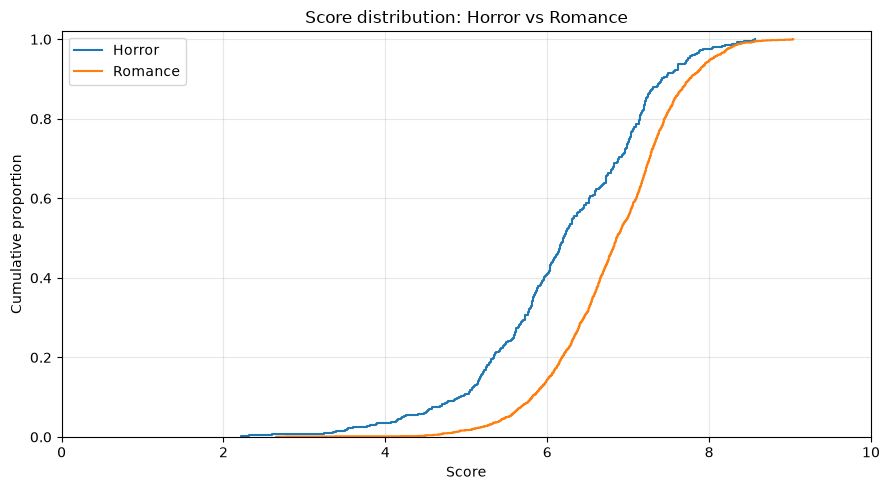

Horror: n=458, mean=6.191
Romance: n=1856, mean=6.822


In [15]:
# Select works containing each genre
horror_scores = anime.loc[
    anime["genres"].str.contains(
        r"\bhorror\b", case=False, na=False
    ),
    "score"
].dropna()

romance_scores = anime.loc[
    anime["genres"].str.contains(
        r"\bromance\b", case=False, na=False
    ),
    "score"
].dropna()

fig, ax = plt.subplots(figsize=(9, 5))

sns.ecdfplot(x=horror_scores, label="Horror", ax=ax)
sns.ecdfplot(x=romance_scores, label="Romance", ax=ax)

ax.set_title("Score distribution: Horror vs Romance")
ax.set_xlabel("Score")
ax.set_ylabel("Cumulative proportion")
ax.set_xlim(0, 10)
ax.set_ylim(0, 1.02)
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

print(f"Horror: n={len(horror_scores)}, mean={horror_scores.mean():.3f}")
print(f"Romance: n={len(romance_scores)}, mean={romance_scores.mean():.3f}")

In [16]:
print(
    f"Horror — score ≤ 6: "
    f"{horror_scores.le(6).mean():.2%}"
)

print(
    f"Romance — score ≤ 6: "
    f"{romance_scores.le(6).mean():.2%}"
)

Horror — score ≤ 6: 41.05%
Romance — score ≤ 6: 14.55%


### Problem 3 — Findings and scoring method

Among rated works, anime has a mean score of 6.418,
while manga has a mean score of 6.945.
Manga scores are more tightly concentrated.

Scores are missing for 8,935 anime and 40,197 manga.
These comparisons therefore describe only rated works.

We defined a weighted score:

W = (v × R + m × C) / (v + m)

- R: original score.
- v: number of voters.
- C: mean score among works with a known score and positive
  voter count, calculated separately for anime and manga.
- m: 1,000, our chosen smoothing parameter.

With few votes, the weighted score moves toward C.
With many votes, it remains close to the original score.
At 1,000 votes, R and C have equal weight.

For example, Blue Giant changes from 7.59 to approximately
6.704 with 322 voters. Fullmetal Alchemist: Brotherhood
changes from 9.10 to approximately 9.099 with 2,037,075 voters.

This method reduces the influence of scores based on few votes.
However, it may disadvantage niche or newly released works.
The choice of m affects rankings and is not universal.
Missing scores remain missing.

### Genre comparison: Horror and Romance

Among rated anime, Horror contains 458 works with a mean
score of 6.191, while Romance contains 1,856 works with
a mean score of 6.822.

41.05% of Horror works have scores at or below 6,
compared with 14.55% of Romance works — a difference
of 26.50 percentage points.

The ECDF shows that Romance scores generally lie higher.
This is a descriptive association, not evidence that genre
causes higher ratings. Works may belong to both genres,
and unrated works are excluded.

### Problem 4. Score and popularity
Try to view the "score" through the lens of the other popularity features. For example, number of times it's been added to favorites. How similar (or different) are score and popularity? Can you figure out any groups (clusters)?

Anime — Spearman correlation: 0.738
Manga — Spearman correlation: 0.641


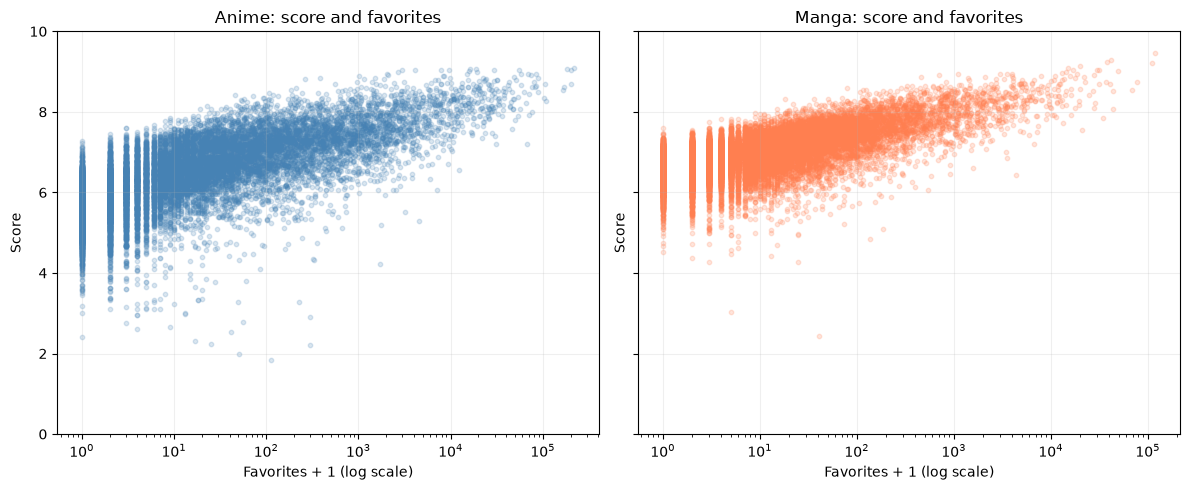

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)

for name, df, ax, color in [
    ("Anime", anime, axes[0], "steelblue"),
    ("Manga", manga, axes[1], "coral")
]:
    data = df[["score", "favorites"]].dropna()

    ax.scatter(
        data["favorites"] + 1,
        data["score"],
        s=10,
        alpha=0.2,
        color=color
    )

    ax.set_xscale("log")
    ax.set_title(f"{name}: score and favorites")
    ax.set_xlabel("Favorites + 1 (log scale)")
    ax.set_ylabel("Score")
    ax.set_ylim(0, 10)
    ax.grid(alpha=0.2)

    correlation = data["score"].corr(
        data["favorites"], method="spearman"
    )
    print(f"{name} — Spearman correlation: {correlation:.3f}")

plt.tight_layout()
plt.show()

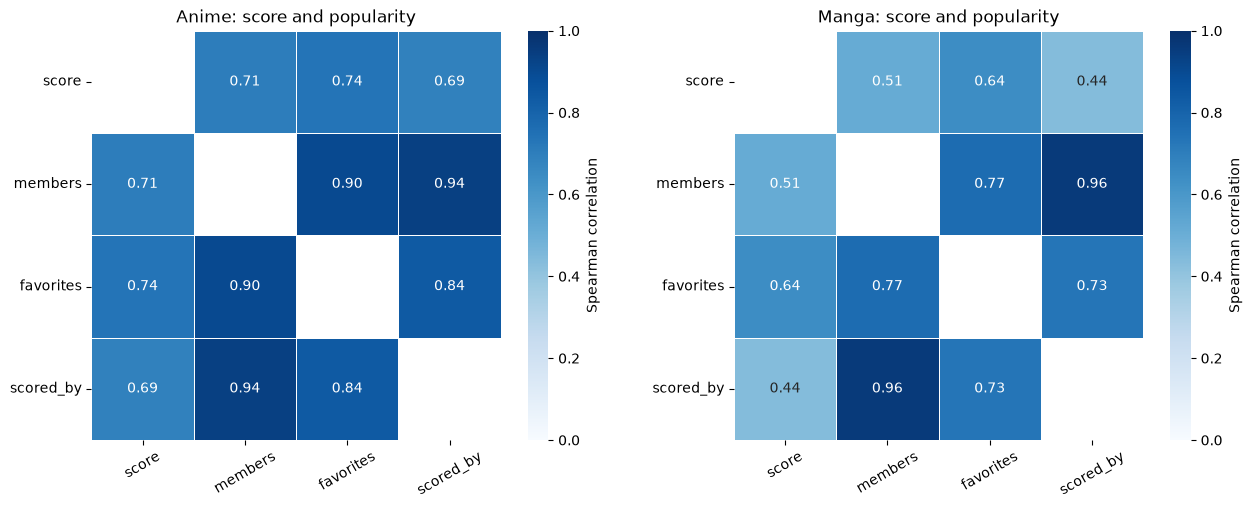

In [18]:
columns = ["score", "members", "favorites", "scored_by"]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for name, df, ax in [
    ("Anime", anime, axes[0]),
    ("Manga", manga, axes[1])
]:
    correlations = df[columns].corr(method="spearman")

    # Hide self-correlations on the diagonal
    mask = pd.DataFrame(
        [
            [row == col for col in columns]
            for row in columns
        ],
        index=columns,
        columns=columns
    )

    sns.heatmap(
        correlations,
        mask=mask,
        annot=True,
        fmt=".2f",
        cmap="Blues",
        vmin=0,
        vmax=1,
        square=True,
        linewidths=0.5,
        cbar_kws={"label": "Spearman correlation"},
        ax=ax
    )

    ax.set_title(f"{name}: score and popularity")
    ax.tick_params(axis="x", rotation=30)
    ax.tick_params(axis="y", rotation=0)

plt.tight_layout()
plt.show()

### Problem 4 — Score and popularity

Scores are positively associated with popularity.
The relationships are stronger for anime than for manga.

Spearman correlations between score and:
- Favorites: 0.74 for anime and 0.64 for manga.
- Members: 0.71 for anime and 0.51 for manga.
- Number of voters: 0.69 for anime and 0.44 for manga.

Members and voter counts are very strongly associated:
0.94 for anime and 0.96 for manga.

Score and popularity describe different aspects of reception.
Works with similar scores can have very different popularity.

The scatter plots suggest continuous relationships rather
than clearly separated clusters. No formal clustering was
performed. Vertical bands at low favorite counts reflect
discrete counts, not necessarily distinct groups.

Correlations do not establish causation. Each correlation
uses records with available values for that pair of features.

### Problem 5. Compare anime and manga visually
You can use the merged dataset, or keep them separate. Select features that you can meaningfully compare across the two mediums and try to draw conclusions. Do they behave similarly? How? If possible, try to explain why; you'll likely need additional "domain" knowledge for this.

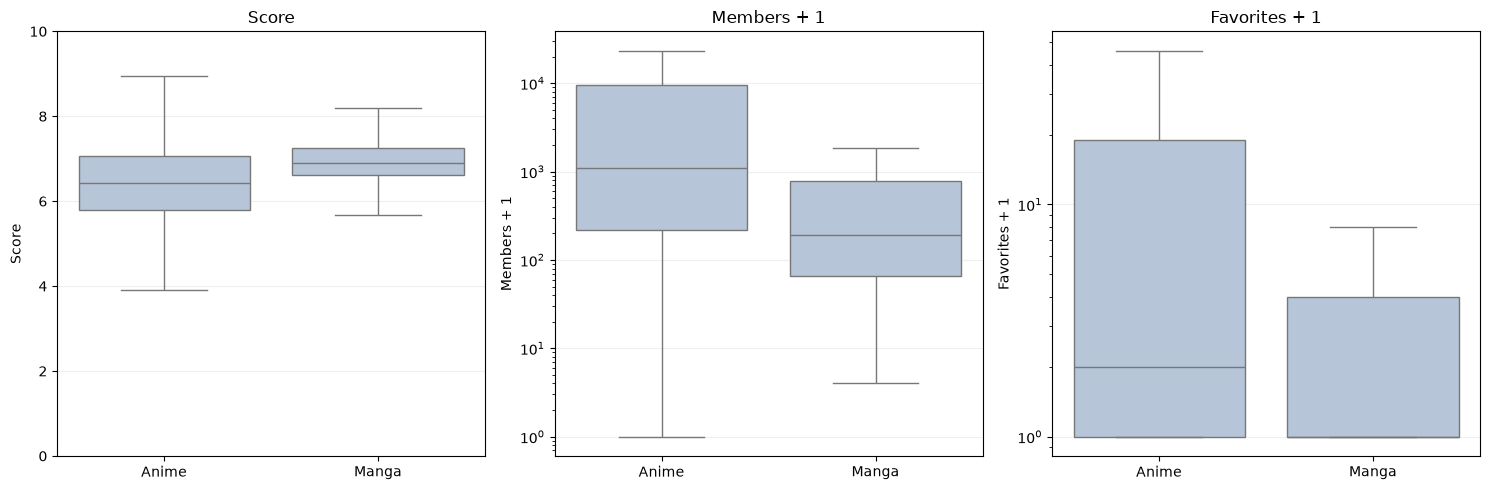

Median values:


,score,members,favorites
medium,,,
Anime,6.42,1085.0,1.0
Manga,6.91,190.0,0.0


In [19]:
comparison = pd.concat(
    [
        anime[["score", "members", "favorites"]].assign(medium="Anime"),
        manga[["score", "members", "favorites"]].assign(medium="Manga")
    ],
    ignore_index=True
)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, column, title in [
    (axes[0], "score", "Score"),
    (axes[1], "members", "Members + 1"),
    (axes[2], "favorites", "Favorites + 1")
]:
    data = comparison[["medium", column]].dropna().copy()

    if column != "score":
        data[column] = data[column] + 1

    sns.boxplot(
        data=data,
        x="medium",
        y=column,
        order=["Anime", "Manga"],
        color="lightsteelblue",
        showfliers=False,
        ax=ax
    )

    if column != "score":
        ax.set_yscale("log")
    else:
        ax.set_ylim(0, 10)

    ax.set_title(title)
    ax.set_xlabel("")
    ax.set_ylabel(title)
    ax.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.show()

print("Median values:")
display(
    comparison.groupby("medium")[
        ["score", "members", "favorites"]
    ].median().round(2)
)

### Problem 5 — Visual comparison of anime and manga

Rated manga has a higher median score (6.91) than rated
anime (6.42), with a narrower middle 50% of scores.

Anime has a higher median membership count:
1,085 compared with 190 for manga.
Median favorites are 1 for anime and 0 for manga.

Both media have strongly right-skewed popularity distributions:
many works receive little attention, while a small number
are highly popular.

Higher ratings therefore do not necessarily imply a larger
audience across media.

Differences may reflect platform usage, catalog composition,
and which works receive ratings. These explanations are
hypotheses, not conclusions established by these plots.

Score comparisons exclude unrated works, while membership
and favorites summaries use all available values.
Outlier points are hidden in the boxplots but retained
in the calculations.

### * Problem 6. Time series
There are a ton of works in the dataset. Most tendencies, when averaged out, will be blurred.

A special type of analysis we can do is _time series_. If you look at the dataset as a function of time, can you find some tendencies across decades, or years, or even seasons? Try to think about volume (counts and frequencies), ratings (are newer works considered better?), genres, etc.

How does the analysis of scores from Problem 3 correspond to "recency", i.e., are recent works (animes / mangas) liked better; or are classics better? Keep in mind that older works have had _more time_ to be evaluated. Come up with one (or more...) definition of "better" and defend it. Pay special attention to the number of voters.

In [20]:
time_summaries = {}

for name, df in [("Anime", anime), ("Manga", manga)]:
    data = df.copy()

    data["release_year"] = pd.to_datetime(
        data["real_start_date"], errors="coerce"
    ).dt.year.astype("Int64")

    print(f"{name}: missing release year = "
          f"{data['release_year'].isna().sum():,}")

    data = data.dropna(subset=["release_year"])
    data["decade"] = (data["release_year"] // 10) * 10

    summary = data.groupby("decade").agg(
        works=("score", "size"),
        rated_works=("score", "count"),
        mean_score=("score", "mean")
    )

    rated = data.loc[data["score"].notna()]

    summary["median_voters"] = (
        rated.groupby("decade")["scored_by"].median()
    )

    established = data.loc[
        data["score"].notna() & data["scored_by"].ge(1000)
    ]

    summary["mean_score_1000"] = (
        established.groupby("decade")["score"].mean()
    )
    summary["works_1000"] = (
        established.groupby("decade").size()
        .reindex(summary.index, fill_value=0)
    )

    summary["rated_percent"] = (
        100 * summary["rated_works"] / summary["works"]
    )

    time_summaries[name] = summary

    print(f"\n{name} — releases from 1970 onward")
    display(summary.loc[1970:].round(2))

Anime: missing release year = 875

Anime — releases from 1970 onward


,works,rated_works,mean_score,median_voters,mean_score_1000,works_1000,rated_percent
decade,,,,,,,
1970,549,347,6.09,364.0,7.01,74,63.21
1980,1497,1032,6.17,548.0,6.72,359,68.94
1990,2389,1622,6.29,894.0,6.75,765,67.89
2000,4795,3575,6.42,2310.0,6.80,2370,74.56
2010,10324,6752,6.46,2928.0,6.84,4436,65.40
2020,3958,2366,6.71,1392.5,7.03,1295,59.78


Manga: missing release year = 1,883

Manga — releases from 1970 onward


,works,rated_works,mean_score,median_voters,mean_score_1000,works_1000,rated_percent
decade,,,,,,,
1970,469,171,7.10,310.0,7.50,37,36.46
1980,1135,347,7.00,300.0,7.51,76,30.57
1990,3721,1331,6.99,440.0,7.52,364,35.77
2000,16961,7801,6.97,502.0,7.34,2335,45.99
2010,33129,11662,6.93,415.5,7.25,3138,35.20
2020,7287,2366,6.95,309.5,7.21,448,32.47


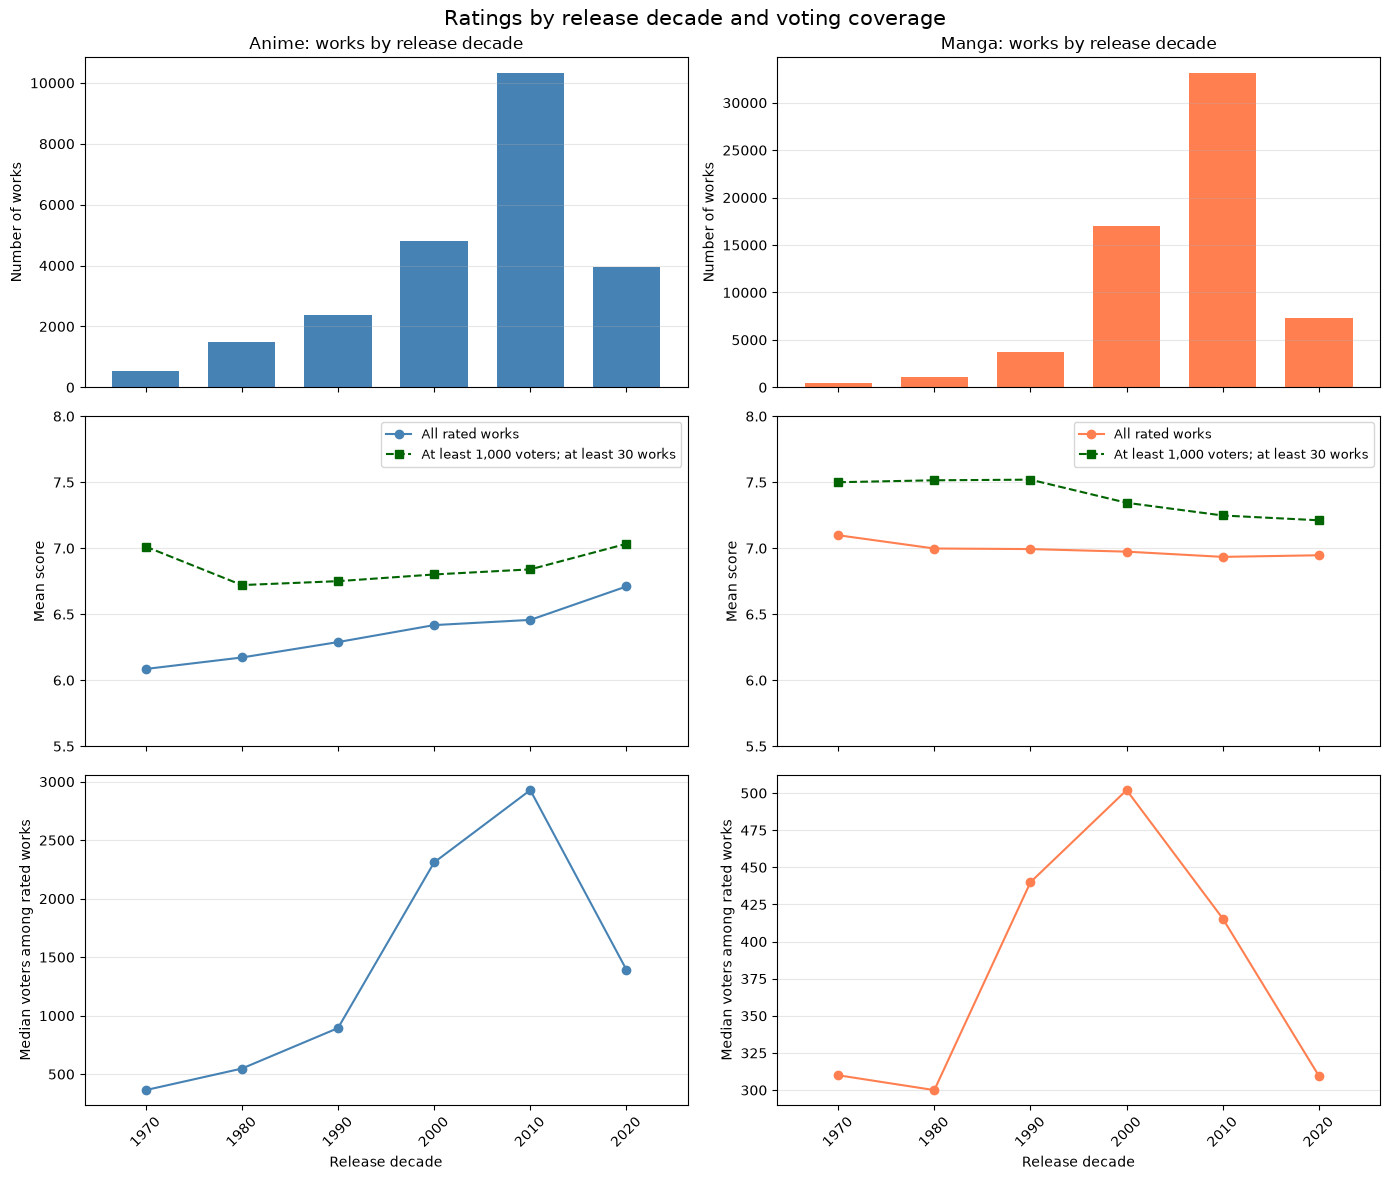

In [21]:
fig, axes = plt.subplots(3, 2, figsize=(14, 12), sharex=True)

for col, (name, color) in enumerate([
    ("Anime", "steelblue"),
    ("Manga", "coral")
]):
    summary = time_summaries[name].loc[1970:]
    years = summary.index.to_numpy(dtype=int)

    axes[0, col].bar(
        years, summary["works"], width=7, color=color
    )
    axes[0, col].set_title(f"{name}: works by release decade")
    axes[0, col].set_ylabel("Number of works")

    axes[1, col].plot(
        years, summary["mean_score"],
        marker="o", color=color, label="All rated works"
    )

    # Avoid interpreting averages based on very few works
    enough_works = summary["works_1000"].ge(30)

    axes[1, col].plot(
        years,
        summary["mean_score_1000"].where(enough_works),
        marker="s", linestyle="--", color="darkgreen",
        label="At least 1,000 voters; at least 30 works"
    )
    axes[1, col].set_ylabel("Mean score")
    axes[1, col].set_ylim(5.5, 8)
    axes[1, col].legend(fontsize=9)

    axes[2, col].plot(
        years, summary["median_voters"],
        marker="o", color=color
    )
    axes[2, col].set_ylabel("Median voters among rated works")
    axes[2, col].set_xlabel("Release decade")

    for row in range(3):
        axes[row, col].set_xticks(years)
        axes[row, col].tick_params(axis="x", rotation=45)
        axes[row, col].grid(axis="y", alpha=0.3)

fig.suptitle(
    "Ratings by release decade and voting coverage",
    fontsize=15
)
plt.tight_layout()
plt.show()

### Problem 6 — Release decades, ratings and voting coverage

Recorded release counts rise substantially from the 1970s
to the 2010s in both datasets. The 2020s are incomplete
in this dataset, so their lower counts do not establish
a decline in production.

We use two definitions of better reception:
a higher mean score among rated works, and a higher mean
score among works with at least 1,000 voters.
Each work receives equal weight within its group.

For anime with at least 1,000 voters, mean scores increase
from approximately 6.75 for 1990s releases to 7.03 for
2020s releases. For manga, they decrease from approximately
7.52 to 7.21 over the same release decades.
Thus, the relationship between release period and ratings
differs between the two media.

The 1,000-voter threshold reduces reliance on scores based
on few votes, but favors works that attract more voters.
It may exclude recent or niche titles. Filtered averages
are plotted only for decades with at least 30 eligible works.

Older works have had more time to accumulate votes.
However, voting coverage also depends on popularity and
which older titles are represented on the platform.
Missing scores and release dates further limit comparisons.

These are current dataset scores grouped by release date,
not historical measurements of how ratings changed over time.
The results do not establish that newer works or classics
are inherently better.

### Problem 7. Genres
Turn genres into something tidy and visualize them. You'll need at least one or two additional datasets for this.

**A quick sanity check:** Do the genres for _the same title_ of manga and anime match completely? Why?

Show which genres dominate, which ones are niche, and whether the most common genres are also the most successful by whatever measure you think is reasonable. Be careful: _common_, _beloved_, and _highly rated_ are not the same thing.

Compare genres across both types of media. Can you explain similarities and differences? Try to take into account the `source` column in the `animes.csv` dataset.

In [22]:
import ast


def parse_genres(value):
    if pd.isna(value):
        return []

    parsed = ast.literal_eval(value)

    if not isinstance(parsed, list):
        raise ValueError(f"Expected a list, got: {value}")

    return sorted(set(
        genre.strip()
        for genre in parsed
        if isinstance(genre, str) and genre.strip()
    ))


def make_genre_table(df, id_column):
    columns = [
        id_column, "title", "score",
        "scored_by", "members", "favorites", "genres"
    ]

    if "source" in df.columns:
        columns.append("source")

    tidy = df[columns].copy()
    tidy["genre"] = tidy["genres"].apply(parse_genres)

    tidy = (
        tidy.drop(columns="genres")
        .explode("genre")
        .dropna(subset=["genre"])
        .reset_index(drop=True)
    )

    return tidy


anime_genres = make_genre_table(anime, "anime_id")
manga_genres = make_genre_table(manga, "manga_id")

display(anime_genres.head(10))

,anime_id,title,score,scored_by,members,favorites,source,genre
0,5114,Fullmetal Alchemist: Brotherhood,9.10,2037075,3206028,219036,manga,Action
1,5114,Fullmetal Alchemist: Brotherhood,9.10,2037075,3206028,219036,manga,Adventure
2,5114,Fullmetal Alchemist: Brotherhood,9.10,2037075,3206028,219036,manga,Drama
3,5114,Fullmetal Alchemist: Brotherhood,9.10,2037075,3206028,219036,manga,Fantasy
4,11061,Hunter x Hunter (2011),9.04,1671587,2688079,202109,manga,Action
5,11061,Hunter x Hunter (2011),9.04,1671587,2688079,202109,manga,Adventure
6,11061,Hunter x Hunter (2011),9.04,1671587,2688079,202109,manga,Fantasy
7,38524,Shingeki no Kyojin Season 3 Part 2,9.05,1491491,2133927,55644,manga,Action
8,38524,Shingeki no Kyojin Season 3 Part 2,9.05,1491491,2133927,55644,manga,Drama
9,9253,Steins;Gate,9.07,1348232,2463954,184312,visual_novel,Drama


In [23]:
def summarize_genres(tidy, id_column, total_works):
    summary = tidy.groupby("genre").agg(
        works=(id_column, "nunique"),
        rated_works=("score", "count"),
        median_members=("members", "median"),
        median_favorites=("favorites", "median")
    )

    eligible = tidy.loc[
        tidy["score"].notna()
        & tidy["scored_by"].ge(1000)
    ]

    ratings = eligible.groupby("genre").agg(
        eligible_works=(id_column, "nunique"),
        mean_score_1000=("score", "mean")
    )

    summary = summary.join(ratings)
    summary["eligible_works"] = (
        summary["eligible_works"].fillna(0).astype(int)
    )

    # Hide means based on fewer than 30 eligible works
    summary["mean_score_1000"] = (
        summary["mean_score_1000"]
        .where(summary["eligible_works"].ge(30))
    )

    summary["share_percent"] = (
        100 * summary["works"] / total_works
    )

    return summary.sort_values("works", ascending=False)


anime_genre_summary = summarize_genres(
    anime_genres, "anime_id", len(anime)
)
manga_genre_summary = summarize_genres(
    manga_genres, "manga_id", len(manga)
)

for name, summary in [
    ("Anime", anime_genre_summary),
    ("Manga", manga_genre_summary)
]:
    print(f"\n{name} — most common genres")
    display(summary.head(10).round(2))

    print(f"{name} — least common recorded genres")
    display(summary.tail(5).round(2))


Anime — most common genres


,works,rated_works,median_members,median_favorites,eligible_works,mean_score_1000,share_percent
genre,,,,,,,
Comedy,7154,5165,2707.5,3.0,3437,6.87,28.63
Fantasy,5326,3379,1729.5,2.0,2213,6.94,21.32
Action,4744,4020,7927.0,14.0,2898,6.95,18.99
Adventure,3841,2713,2484.0,4.0,1774,7.00,15.37
Sci-Fi,3108,2481,4444.0,6.0,1746,6.85,12.44
Drama,2839,2220,7239.0,12.0,1675,7.13,11.36
Romance,2065,1856,20245.0,38.0,1527,6.98,8.26
Slice of Life,1701,1167,1239.0,1.0,664,6.92,6.81
Supernatural,1489,1284,12771.0,19.0,985,7.00,5.96


Anime — least common recorded genres


,works,rated_works,median_members,median_favorites,eligible_works,mean_score_1000,share_percent
genre,,,,,,,
Award Winning,240,214,42697.5,182.0,177,7.61,0.96
Boys Love,168,151,18540.5,65.0,133,6.57,0.67
Gourmet,149,113,3809.0,6.0,74,6.94,0.60
Girls Love,113,104,27206.0,69.0,93,6.72,0.45
Erotica,58,47,13517.5,33.5,40,6.39,0.23



Manga — most common genres


,works,rated_works,median_members,median_favorites,eligible_works,mean_score_1000,share_percent
genre,,,,,,,
Romance,16876,7806,310.0,1.0,2575,7.27,26.03
Comedy,14099,6504,328.0,1.0,2152,7.28,21.75
Hentai,11208,1932,110.0,0.0,61,7.13,17.29
Fantasy,10952,4585,283.5,1.0,1409,7.28,16.89
Boys Love,9610,5154,335.0,0.0,957,7.38,14.82
Drama,9303,4997,460.0,1.0,1741,7.48,14.35
Action,8910,4034,354.0,1.0,1495,7.31,13.74
Erotica,8844,4823,346.0,0.0,884,7.24,13.64
Supernatural,7471,3197,270.0,1.0,1005,7.37,11.52


Manga — least common recorded genres


,works,rated_works,median_members,median_favorites,eligible_works,mean_score_1000,share_percent
genre,,,,,,,
Sports,1116,405,177.0,0.0,133,7.55,1.72
Suspense,519,217,292.0,1.0,101,7.43,0.80
Award Winning,439,316,2479.0,37.0,199,8.09,0.68
Gourmet,410,122,141.0,0.0,35,7.53,0.63
Avant Garde,70,35,399.5,1.0,4,NaN,0.11


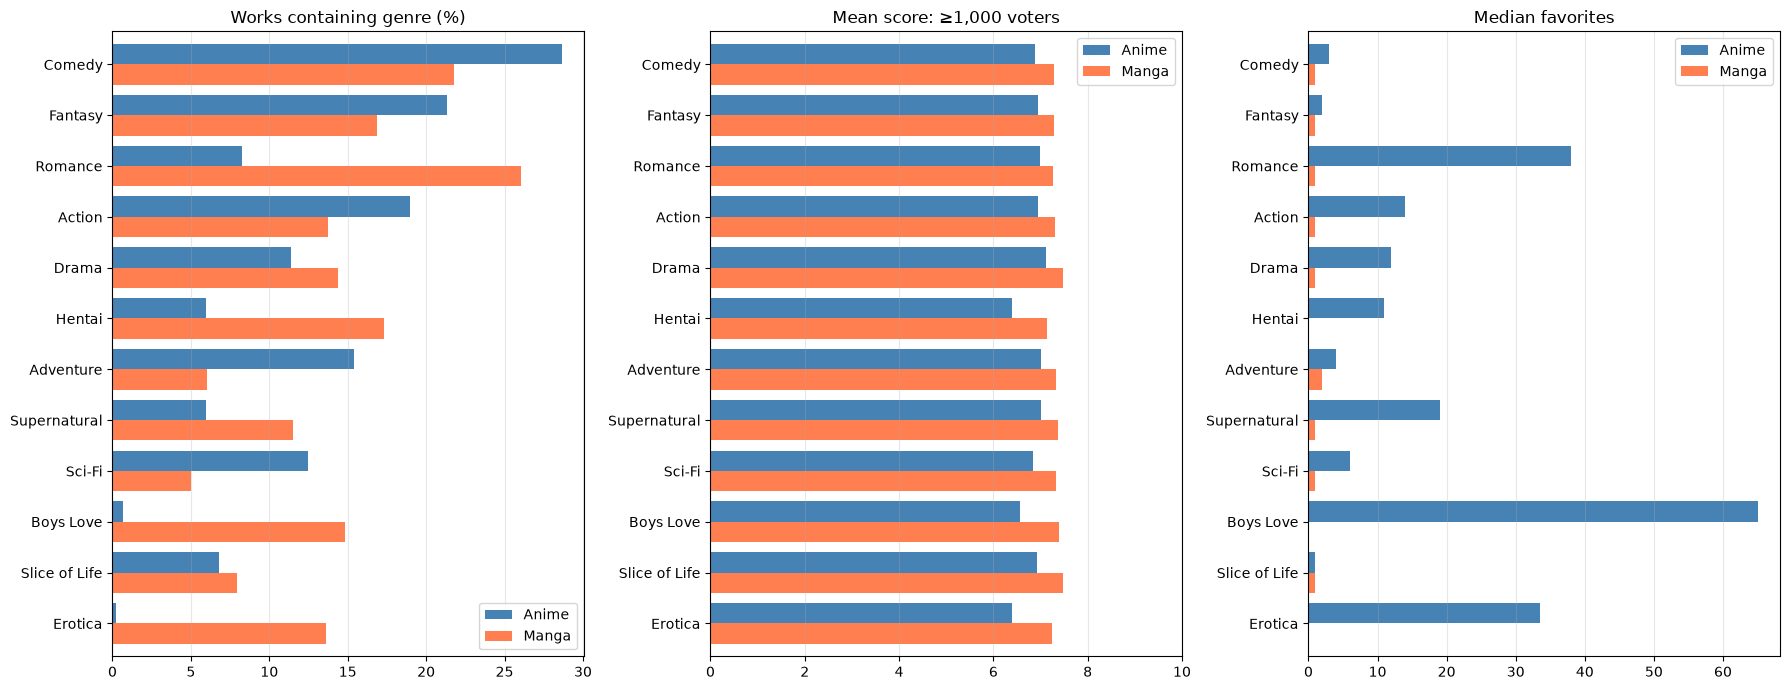

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(18, 7))

top_genres = (
    anime_genre_summary["share_percent"]
    .add(
        manga_genre_summary["share_percent"],
        fill_value=0
    )
    .nlargest(12)
    .index
)

for ax, metric, title in [
    (axes[0], "share_percent", "Works containing genre (%)"),
    (axes[1], "mean_score_1000", "Mean score: ≥1,000 voters"),
    (axes[2], "median_favorites", "Median favorites")
]:
    comparison = pd.DataFrame({
        "Anime": anime_genre_summary[metric],
        "Manga": manga_genre_summary[metric]
    }).reindex(top_genres)

    comparison.plot.barh(
        ax=ax,
        color=["steelblue", "coral"],
        width=0.8
    )

    ax.invert_yaxis()
    ax.set_title(title)
    ax.set_ylabel("")
    ax.grid(axis="x", alpha=0.3)

axes[1].set_xlim(0, 10)

plt.tight_layout()
plt.show()

In [25]:
def prepare_title_matches(df, id_column):
    result = df[[id_column, "title", "genres"]].copy()

    result["title_key"] = (
        result["title"]
        .str.casefold()
        .str.replace(r"\s+", " ", regex=True)
        .str.strip()
    )

    result["genre_set"] = result["genres"].apply(
        lambda value: frozenset(parse_genres(value))
    )

    # Avoid ambiguous titles within each dataset
    unique_title = ~result["title_key"].duplicated(keep=False)

    return result.loc[
        unique_title & result["title_key"].ne("")
    ]


title_matches = prepare_title_matches(
    anime, "anime_id"
).merge(
    prepare_title_matches(manga, "manga_id"),
    on="title_key",
    suffixes=("_anime", "_manga")
)

# Compare only pairs with recorded genres on both sides
comparable = title_matches.loc[
    title_matches["genre_set_anime"].map(bool)
    & title_matches["genre_set_manga"].map(bool)
].copy()

comparable["same_genres"] = (
    comparable["genre_set_anime"]
    == comparable["genre_set_manga"]
)

print("Comparable title matches:", len(comparable))

if len(comparable):
    print(
        "Identical genre sets:",
        f"{comparable['same_genres'].mean():.2%}"
    )

display(
    comparable.loc[
        ~comparable["same_genres"],
        ["title_anime", "genres_anime", "genres_manga"]
    ].head(10)
)

Comparable title matches: 2451
Identical genre sets: 41.62%


,title_anime,genres_anime,genres_manga
0,Kimi no Na wa.,"['Award Winning', 'Drama', 'Supernatural']","['Drama', 'Supernatural']"
1,Code Geass: Hangyaku no Lelouch R2,"['Action', 'Award Winning', 'Drama', 'Sci-Fi']","['Action', 'Drama', 'Sci-Fi']"
4,Jujutsu Kaisen,"['Action', 'Award Winning', 'Fantasy']","['Action', 'Supernatural']"
5,Shigatsu wa Kimi no Uso,"['Drama', 'Romance']","['Award Winning', 'Drama', 'Romance']"
6,Shingeki no Kyojin,"['Action', 'Award Winning', 'Drama', 'Suspense']","['Action', 'Award Winning', 'Drama']"
7,Cowboy Bebop,"['Action', 'Award Winning', 'Sci-Fi']","['Action', 'Adventure', 'Sci-Fi']"
9,Vinland Saga,"['Action', 'Adventure', 'Drama']","['Action', 'Adventure', 'Award Winning', 'Drama']"
10,Kimetsu no Yaiba,"['Action', 'Award Winning', 'Fantasy']","['Action', 'Fantasy']"
11,Yakusoku no Neverland,"['Fantasy', 'Mystery', 'Sci-Fi', 'Suspense']","['Award Winning', 'Mystery', 'Sci-Fi', 'Suspen..."
12,Spy x Family,"['Action', 'Award Winning', 'Comedy']","['Action', 'Comedy']"


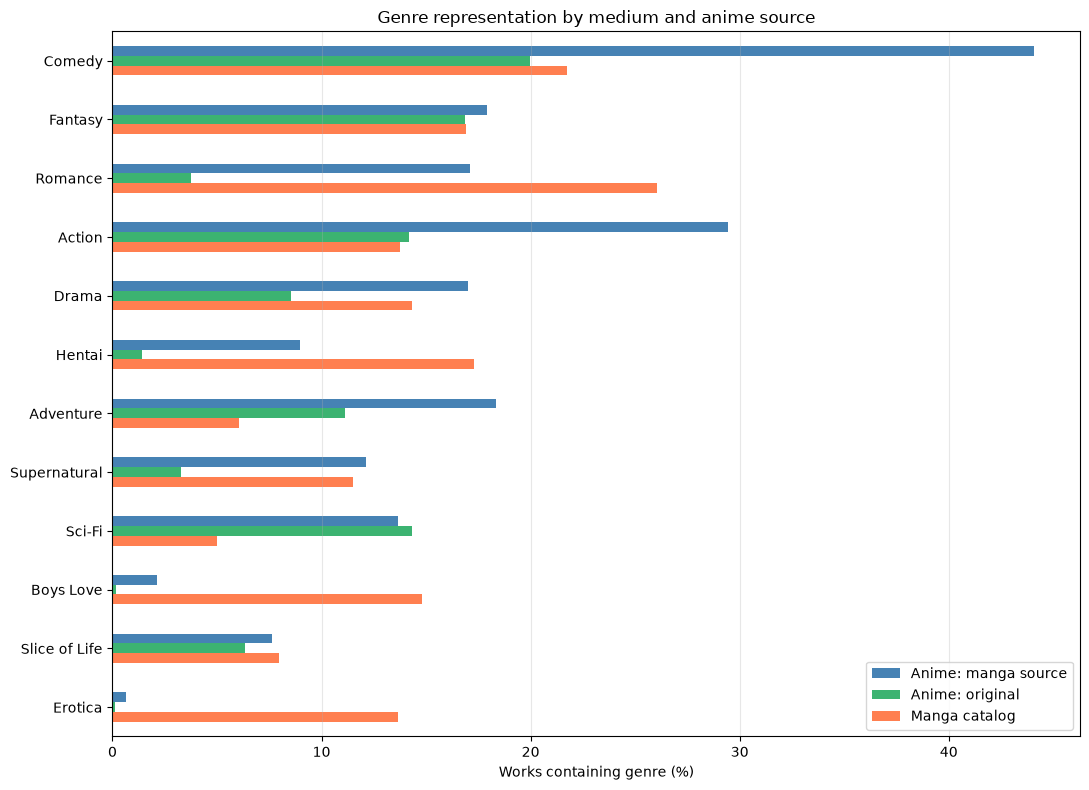

In [26]:
source_comparison = pd.DataFrame({
    "Anime: manga source": (
        anime_genres.loc[anime_genres["source"].eq("manga")]
        .groupby("genre")["anime_id"].nunique()
        .div(anime["source"].eq("manga").sum())
        .mul(100)
    ),
    "Anime: original": (
        anime_genres.loc[anime_genres["source"].eq("original")]
        .groupby("genre")["anime_id"].nunique()
        .div(anime["source"].eq("original").sum())
        .mul(100)
    ),
    "Manga catalog": manga_genre_summary["share_percent"]
}).fillna(0)

ax = source_comparison.reindex(top_genres).plot.barh(
    figsize=(11, 8),
    color=["steelblue", "mediumseagreen", "coral"]
)

ax.invert_yaxis()
ax.set_title("Genre representation by medium and anime source")
ax.set_xlabel("Works containing genre (%)")
ax.set_ylabel("")
ax.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

### Problem 7 — Genres

We created two tidy tables, with one row per work and genre.
A work can belong to several genres, so percentages may
sum to more than 100%.

Genre frequency, ratings and favorites measure different
aspects of reception. Romance is the most common manga
genre (26.03%), but its mean score among works with at least
1,000 voters is 7.27. Sports is less common (1.72%) but has
a higher mean score of 7.55 under the same filter.

Rating means are shown only for genres with at least
30 eligible works. These filtered results do not represent
all works in each genre. Favorites also depend on audience
size, so they are an imperfect measure of being beloved.

Among 2,451 unambiguous exact-title matches with recorded
genres on both sides, 41.62% have identical genre sets.
Title matching identifies candidate pairs, not verified
adaptation relationships. Some differences involve
Award Winning, which is an award label rather than
a narrative genre. Other differences may reflect
classification choices or adaptation scope.

Comedy and Action are more strongly represented among
manga-source anime than in the manga catalog.
Original anime has a larger Sci-Fi share than the manga
catalog. These patterns may reflect adaptation selection
and catalog composition; they do not establish causes
or measure a manga title's probability of adaptation.

The source comparison uses the exact category "manga";
web_manga and 4_koma_manga are excluded from that group.
Works without recorded genres do not contribute genre
rows, but remain in the percentage denominators.

### * Problem 8. Themes and demographics
As a continuation of the last problem, try to explore, visualize, and come up with useful metrics for themes and demographics. A big challenge that you'll face is that a lot of these values (more than half) are actually missing. You'll have to comment on what's missing and why (in case you haven't already done so last time), if you could fill in the values somehow, and how to handle the info that you do have.

Think **very** carefully about what biases might the missing information leave in the data (e.g., smaller productions are not as well-represented because nobody cared enough to fill the information in the site).

In [27]:
label_tables = {}
coverage_rows = []
missingness_rows = []

for medium, df, id_column in [
    ("Anime", anime, "anime_id"),
    ("Manga", manga, "manga_id")
]:
    for feature in ["themes", "demographics"]:
        labels = df[feature].apply(parse_genres)
        has_labels = labels.map(bool)

        coverage_rows.append({
            "medium": medium,
            "feature": feature,
            "total_works": len(df),
            "without_labels": (~has_labels).sum(),
            "without_labels_percent": 100 * (~has_labels).mean()
        })

        # Compare works with and without recorded labels
        for recorded in [True, False]:
            subset = df.loc[has_labels.eq(recorded)]

            missingness_rows.append({
                "medium": medium,
                "feature": feature,
                "labels_recorded": recorded,
                "works": len(subset),
                "median_members": subset["members"].median(),
                "rated_percent": 100 * subset["score"].notna().mean()
            })

        tidy = df[
            [id_column, "score", "scored_by", "members", "favorites"]
        ].copy()

        tidy["label"] = labels
        tidy = tidy.explode("label").dropna(subset=["label"])

        summary = tidy.groupby("label").agg(
            works=(id_column, "nunique"),
            median_members=("members", "median"),
            median_favorites=("favorites", "median")
        )

        eligible = tidy.loc[
            tidy["score"].notna()
            & tidy["scored_by"].ge(1000)
        ]

        ratings = eligible.groupby("label").agg(
            eligible_works=(id_column, "nunique"),
            mean_score_1000=("score", "mean")
        )

        summary = summary.join(ratings)
        summary["eligible_works"] = (
            summary["eligible_works"].fillna(0).astype(int)
        )

        summary["mean_score_1000"] = (
            summary["mean_score_1000"]
            .where(summary["eligible_works"].ge(30))
        )

        # Two denominators answer different questions
        summary["percent_all_works"] = (
            100 * summary["works"] / len(df)
        )
        summary["percent_labeled_works"] = (
            100 * summary["works"] / has_labels.sum()
            if has_labels.sum() else float("nan")
        )

        label_tables[(medium, feature)] = (
            summary.sort_values("works", ascending=False)
        )

coverage = pd.DataFrame(coverage_rows)
missingness = pd.DataFrame(missingness_rows)

print("Missing-label coverage:")
display(coverage.round(2))

print("Popularity and rating coverage:")
display(missingness.round(2))

Missing-label coverage:


,medium,feature,total_works,without_labels,without_labels_percent
0,Anime,themes,24985,11020,44.11
1,Anime,demographics,24985,15471,61.92
2,Manga,themes,64833,40536,62.52
3,Manga,demographics,64833,38491,59.37


Popularity and rating coverage:


,medium,feature,labels_recorded,works,median_members,rated_percent
0,Anime,themes,True,13965,1917.0,70.97
1,Anime,themes,False,11020,631.0,55.71
2,Anime,demographics,True,9514,360.5,47.24
3,Anime,demographics,False,15471,1789.0,74.69
4,Manga,themes,True,24297,309.0,44.81
5,Manga,themes,False,40536,153.0,33.92
6,Manga,demographics,True,26342,248.0,42.73
7,Manga,demographics,False,38491,168.0,34.76


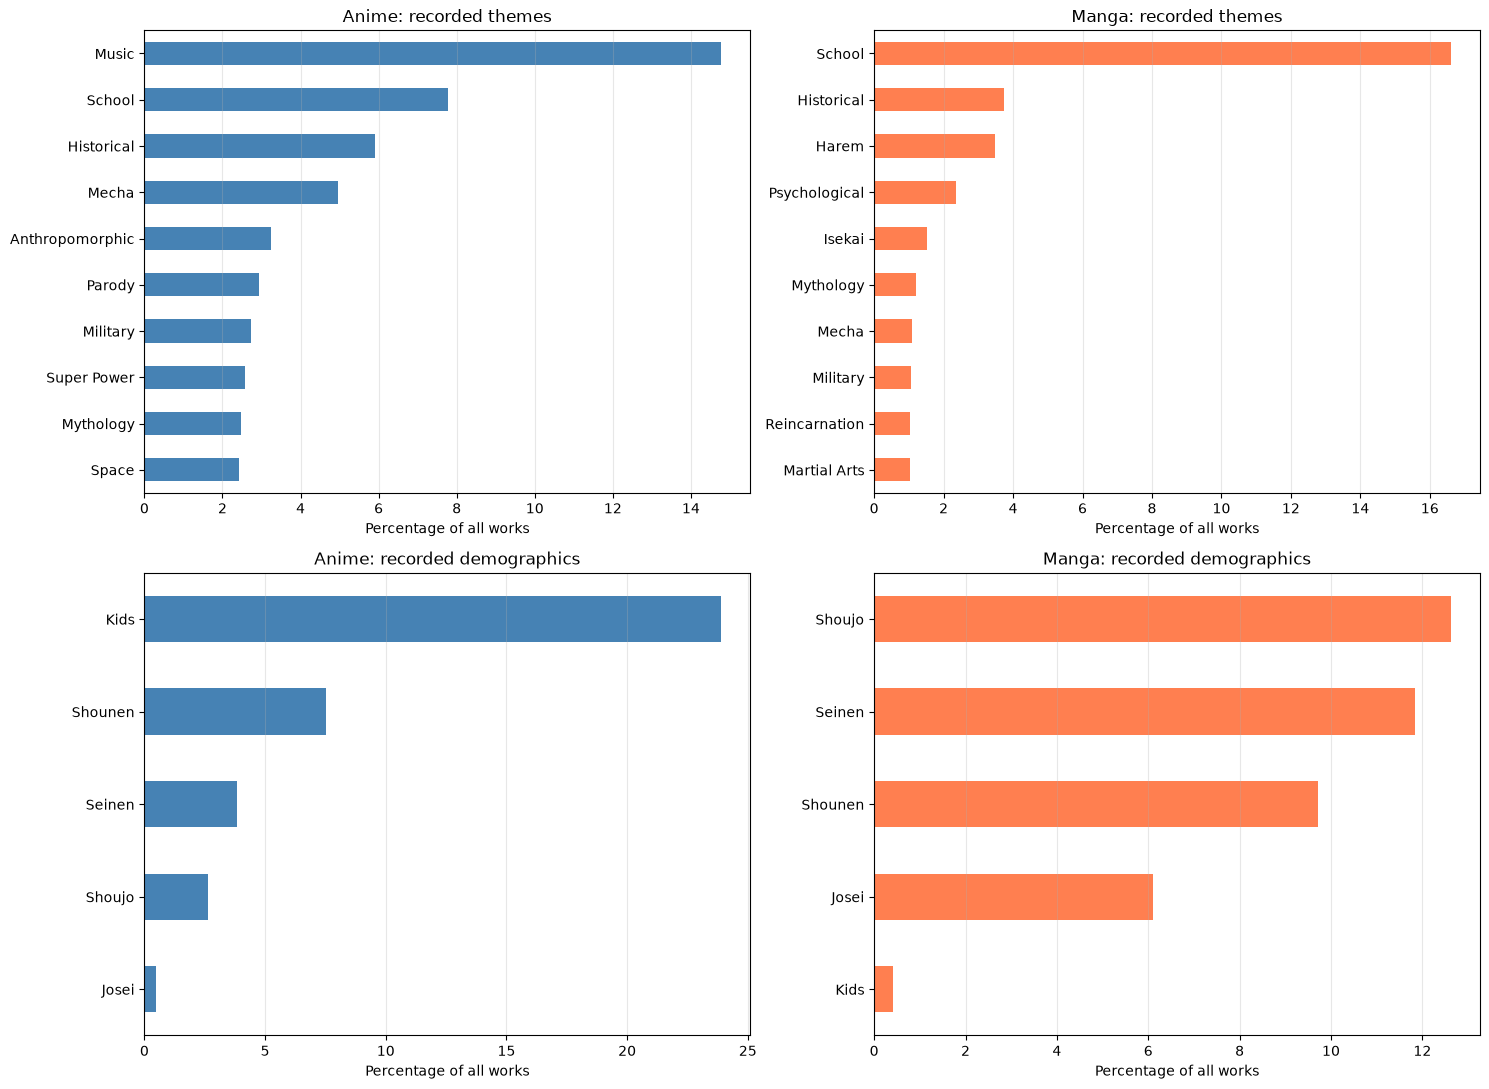


Anime — themes: most common labels


,works,median_members,median_favorites,eligible_works,mean_score_1000,percent_all_works,percent_labeled_works
label,,,,,,,
Music,3693,328.0,0.0,578,6.87,14.78,26.44
School,1946,24132.5,41.0,1430,7.02,7.79,13.93
Historical,1478,1178.0,2.0,530,7.17,5.92,10.58
Mecha,1241,4177.0,5.0,689,6.85,4.97,8.89
Anthropomorphic,809,54.0,0.0,100,7.15,3.24,5.79
Parody,736,1956.0,1.0,311,6.83,2.95,5.27
Military,680,10811.0,15.0,459,7.08,2.72,4.87
Super Power,642,12246.0,15.0,414,6.97,2.57,4.60
Mythology,618,7013.5,16.5,378,7.01,2.47,4.43



Anime — demographics: most common labels


,works,median_members,median_favorites,eligible_works,mean_score_1000,percent_all_works,percent_labeled_works
label,,,,,,,
Kids,5973,110.0,0.0,294,6.79,23.91,62.78
Shounen,1881,25550.0,41.0,1442,7.28,7.53,19.77
Seinen,962,21197.0,31.5,742,7.11,3.85,10.11
Shoujo,655,6264.0,17.0,406,7.06,2.62,6.88
Josei,120,28472.0,69.0,99,6.97,0.48,1.26



Manga — themes: most common labels


,works,median_members,median_favorites,eligible_works,mean_score_1000,percent_all_works,percent_labeled_works
label,,,,,,,
School,10771,334.0,1.0,1792,7.29,16.61,44.33
Historical,2426,200.0,1.0,243,7.68,3.74,9.98
Harem,2255,114.0,0.0,292,6.96,3.48,9.28
Psychological,1532,853.5,4.0,450,7.40,2.36,6.31
Isekai,995,969.0,4.0,269,7.21,1.53,4.10
Mythology,783,332.0,1.0,103,7.46,1.21,3.22
Mecha,698,333.5,1.0,46,7.38,1.08,2.87
Military,679,229.0,1.0,60,7.75,1.05,2.79
Reincarnation,666,798.5,2.0,148,7.30,1.03,2.74



Manga — demographics: most common labels


,works,median_members,median_favorites,eligible_works,mean_score_1000,percent_all_works,percent_labeled_works
label,,,,,,,
Shoujo,8188,359.0,1.0,1209,7.32,12.63,31.08
Seinen,7680,259.0,1.0,1154,7.25,11.85,29.15
Shounen,6297,414.0,1.0,1259,7.30,9.71,23.90
Josei,3960,45.0,0.0,163,7.33,6.11,15.03
Kids,262,155.5,1.0,10,NaN,0.40,0.99


In [28]:
fig, axes = plt.subplots(2, 2, figsize=(15, 11))

for row, feature in enumerate(["themes", "demographics"]):
    for col, medium in enumerate(["Anime", "Manga"]):
        summary = label_tables[(medium, feature)].head(10)
        ax = axes[row, col]

        summary["percent_all_works"].sort_values().plot.barh(
            ax=ax,
            color="steelblue" if medium == "Anime" else "coral"
        )

        ax.set_title(f"{medium}: recorded {feature}")
        ax.set_xlabel("Percentage of all works")
        ax.set_ylabel("")
        ax.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

for key, summary in label_tables.items():
    print(f"\n{key[0]} — {key[1]}: most common labels")
    display(summary.head(10).round(2))

### Problem 8 — Themes, demographics and missing labels

Theme labels are absent for 44.11% of anime and 62.52%
of manga. Demographic labels are absent for 61.92% of
anime and 59.37% of manga. An empty list means no label
is recorded, not that a work has no theme or target audience.

For themes, labeled works have larger median membership
counts than unlabeled works: 1,917 versus 631 for anime,
and 309 versus 153 for manga. They also more frequently
have scores. This is consistent with uneven metadata
coverage, but does not establish why labels are missing.

Anime demographics show the opposite pattern:
unlabeled works have a larger median membership count
(1,789 versus 360.5) and higher rating coverage
(74.69% versus 47.24%).
Kids accounts for 62.78% of demographically labeled anime
and has a low median membership count of 110.
Group composition may therefore help explain this pattern.
Missing labels cannot simply be attributed to low popularity.

Music is the most common recorded anime theme (14.78%
of all anime), while School leads manga themes (16.61%).
Kids is the most common recorded anime demographic;
Shoujo leads the recorded manga demographics.
These distributions describe available labels, not the
unknown distribution among unlabeled works.

Frequency, popularity and ratings measure different things.
For example, School anime has a much larger median
membership count than Music anime (24,132.5 versus 328),
although Music is more common.

Rating comparisons include only works with at least
1,000 voters, and means are hidden when fewer than
30 works qualify. This favors works with larger voting
audiences and limits generalization to niche titles.

Percentages are reported relative to both all works and
labeled works. Multiple labels can occur on one work,
so percentages need not sum to 100%.
Demographic labels describe intended audiences, not
the actual demographics of platform users.

We retain missing labels rather than filling them with
the most common category. Reliable recovery would require
verified information for each work, with its source recorded.
Differences in catalog composition, labeling conventions
and documentation effort are possible explanations for
missingness, but are not established by this analysis.

### Problem 9. The production side
Choose one production-side feature - studios, producers, publishers, authors, serializations, or something similar - and visualize it. Optionally, you could explore all features.

Try to make the plot reveal something about the structure: who appears often and why? Once again (as we asked before), how do we measure how "popular" or "beloved" something is?

In [29]:
# parse_genres also reads lists of studio names
studio_lists = anime["studios"].apply(parse_genres)

print("Anime without recorded studios:",
      (~studio_lists.map(bool)).sum())

studio_data = anime[
    ["anime_id", "title", "members", "favorites", "score"]
].copy()

studio_data["studio"] = studio_lists

studio_data = (
    studio_data
    .explode("studio")
    .dropna(subset=["studio"])
    .reset_index(drop=True)
)

studio_summary = studio_data.groupby("studio").agg(
    works=("anime_id", "nunique"),
    median_members=("members", "median"),
    median_favorites=("favorites", "median"),
    rated_works=("score", "count")
).sort_values("works", ascending=False)

print("Most frequently recorded studios:")
display(studio_summary.head(15).round(2))

Anime without recorded studios: 10418
Most frequently recorded studios:


,works,median_members,median_favorites,rated_works
studio,,,,
Toei Animation,866,2545.0,3.0,728
Sunrise,554,6591.0,11.5,528
J.C.Staff,412,22153.0,29.5,391
Madhouse,372,18694.0,33.5,362
Production I.G,345,23887.0,28.0,328
TMS Entertainment,345,7560.0,8.0,295
Shanghai Animation Film Studio,337,74.0,0.0,8
Studio Deen,316,19781.5,39.5,291
OLM,283,7816.0,8.0,258


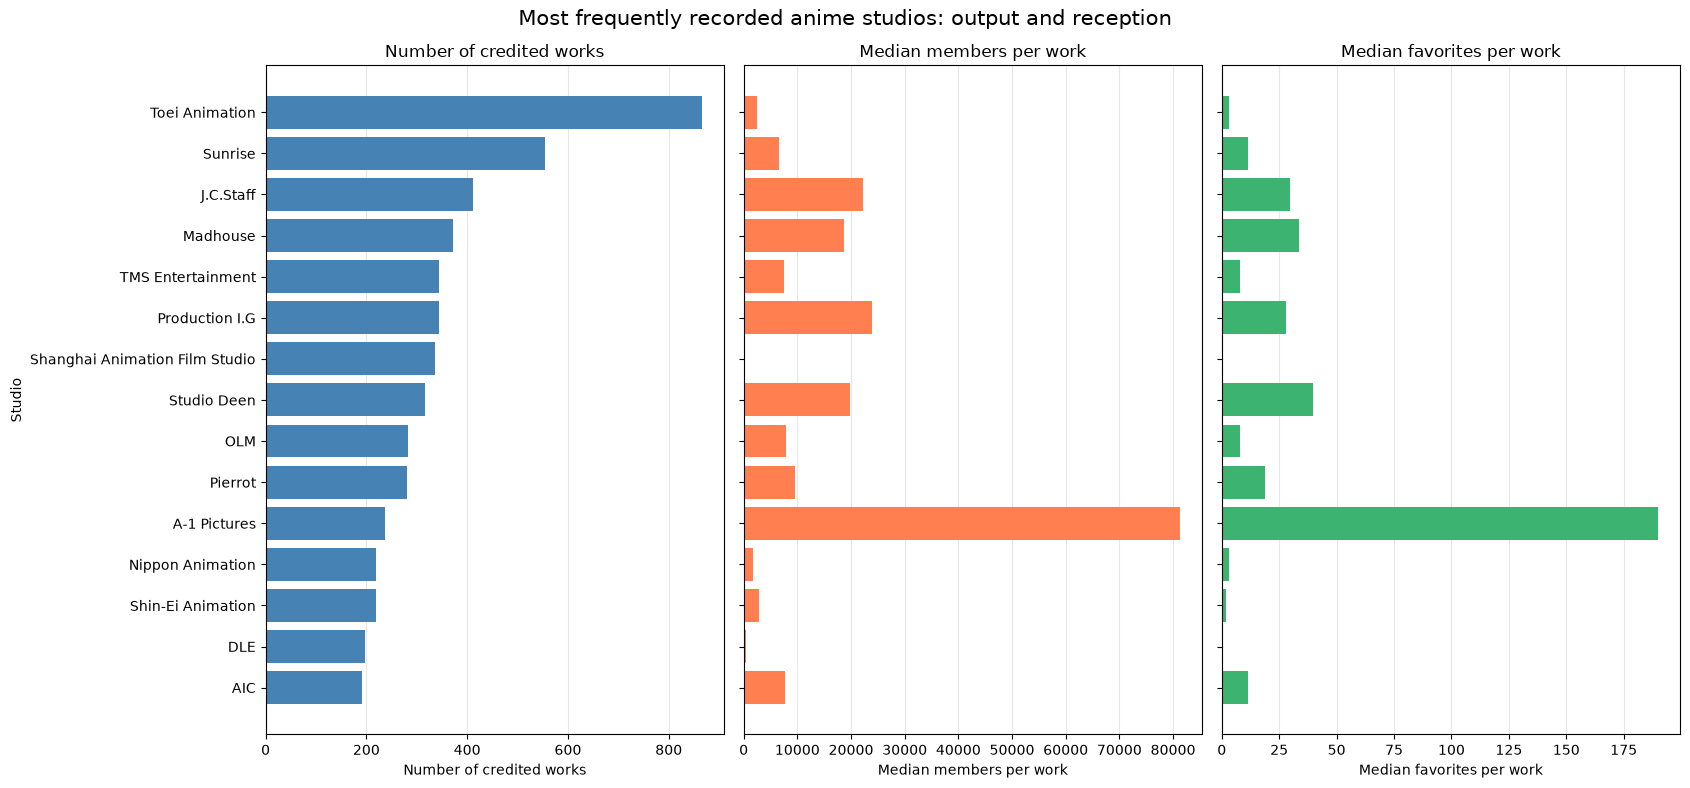

In [30]:
top_studios = studio_summary.head(15).sort_values("works")

fig, axes = plt.subplots(1, 3, figsize=(17, 8), sharey=True)

for ax, metric, title, color in [
    (axes[0], "works",
     "Number of credited works", "steelblue"),
    (axes[1], "median_members",
     "Median members per work", "coral"),
    (axes[2], "median_favorites",
     "Median favorites per work", "mediumseagreen")
]:
    ax.barh(
        top_studios.index,
        top_studios[metric],
        color=color
    )

    ax.set_title(title)
    ax.set_xlabel(title)
    ax.grid(axis="x", alpha=0.3)
    ax.set_axisbelow(True)

axes[0].set_ylabel("Studio")

fig.suptitle(
    "Most frequently recorded anime studios: output and reception",
    fontsize=15
)

plt.tight_layout()
plt.show()

### Problem 9 — Studios: output and reception

Toei Animation has the most credited works in this dataset
(866), followed by Sunrise (554) and J.C.Staff (412).

However, production count does not directly indicate
audience size or attachment. Among the 15 most frequently
recorded studios, A-1 Pictures has the highest median
membership count (81,310) and median favorites (190),
despite having fewer credited works (237).

Shanghai Animation Film Studio illustrates a different
pattern: 337 credited works, but only 74 median members,
zero median favorites and 8 rated works. This describes
its representation and reception on this platform;
it does not establish low quality or low popularity elsewhere.

We measure typical platform popularity using median
members per work, and attachment using median favorites.
Favorites also depend on audience size, so they are
an imperfect measure of being beloved. Medians reduce
the influence of individual blockbuster titles.

High work counts may reflect a longer production history,
many short productions or separately recorded seasons.
These are possible explanations requiring further analysis,
not causes established by these plots.

Studio information is absent for 10,418 anime.
These works are excluded from studio comparisons.
Co-produced works count once for each credited studio,
so studio totals can exceed the number of unique works.
The results describe recorded credits, not production
budgets, workload or the entire anime industry.

### * Problem 10. Scores by production
Revisit your analysis in the previous problems where you explored scores and popularity. Now compare with studios / producers. 

Are there universally liked studios? Are there some which only make one very niche thing, a cult classic? How does production (and reception) compare across the two types of work? Document your findings.

In [31]:
# Anime: reuse the studio table from Problem 9
anime_production = studio_data.rename(
    columns={"studio": "creator"}
).copy()

anime_production["scored_by"] = anime_production["anime_id"].map(
    anime.set_index("anime_id")["scored_by"]
)


# Manga: authors are stored as lists of dictionaries
def extract_authors(value):
    if pd.isna(value):
        return []

    authors = ast.literal_eval(value)

    return list(dict.fromkeys(
        (
            str(author["id"]),
            " ".join(
                str(author.get(part) or "").strip()
                for part in ["first_name", "last_name"]
            ).strip()
        )
        for author in authors
    ))


manga_production = manga[
    ["manga_id", "title", "score", "scored_by", "members", "favorites"]
].copy()

manga_production["author"] = manga["authors"].apply(
    extract_authors
)

manga_production = (
    manga_production.explode("author")
    .dropna(subset=["author"])
    .copy()
)

manga_production["creator_id"] = manga_production["author"].map(
    lambda author: author[0]
)
manga_production["creator"] = manga_production["author"].map(
    lambda author: author[1]
)

In [32]:
def production_scores(data, id_column, group_column):
    totals = data.groupby(group_column).agg(
        works=(id_column, "nunique"),
        median_members=("members", "median"),
        median_favorites=("favorites", "median")
    )

    eligible = data.loc[
        data["score"].notna()
        & data["scored_by"].ge(1000)
    ]

    reception = eligible.groupby(group_column).agg(
        eligible_works=(id_column, "nunique"),
        mean_score=("score", "mean"),
        median_score=("score", "median"),
        lower_quartile=("score", lambda scores: scores.quantile(0.25)),
        minimum_score=("score", "min"),
        percent_score_8=("score", lambda scores: 100 * scores.ge(8).mean())
    )

    result = totals.join(reception)
    result["eligible_works"] = (
        result["eligible_works"].fillna(0).astype(int)
    )
    result["eligible_percent"] = (
        100 * result["eligible_works"] / result["works"]
    )

    return result


studio_scores = production_scores(
    anime_production, "anime_id", "creator"
)

author_scores = production_scores(
    manga_production, "manga_id", "creator_id"
)

author_names = (
    manga_production.drop_duplicates("creator_id")
    .set_index("creator_id")["creator"]
)

author_scores["creator"] = author_names

for name, summary in [
    ("Anime studios", studio_scores),
    ("Manga authors", author_scores)
]:
    print(f"\n{name}: highest mean scores, ≥10 eligible works")

    display(
        summary.loc[summary["eligible_works"].ge(10)]
        .sort_values("mean_score", ascending=False)
        .head(10)
        .round(2)
    )
    


Anime studios: highest mean scores, ≥10 eligible works


,works,median_members,median_favorites,eligible_works,mean_score,median_score,lower_quartile,minimum_score,percent_score_8,eligible_percent
creator,,,,,,,,,,
Shuka,21,53399.0,57.0,18,7.71,7.90,7.46,5.65,38.89,85.71
Motion Magic,14,5040.5,34.5,10,7.68,7.61,7.53,7.33,20.00,71.43
Animation Do,10,75992.5,124.0,10,7.63,7.62,7.59,7.33,0.00,100.00
Bandai Namco Pictures,61,5246.0,20.0,39,7.51,7.43,6.99,5.96,25.64,63.93
TROYCA,21,23982.0,197.0,15,7.48,7.52,7.24,6.08,20.00,71.43
Wit Studio,82,44219.0,77.5,60,7.45,7.48,7.19,5.26,21.67,73.17
Kitty Film Mitaka Studio,17,4149.0,2.0,10,7.42,7.12,6.90,6.61,20.00,58.82
B.CMAY PICTURES,19,13865.0,71.0,13,7.41,7.72,6.82,6.02,23.08,68.42
MAPPA,83,75678.0,261.0,66,7.40,7.39,6.82,5.38,25.76,79.52



Manga authors: highest mean scores, ≥10 eligible works


,works,median_members,median_favorites,eligible_works,mean_score,median_score,lower_quartile,minimum_score,percent_score_8,eligible_percent,creator
creator_id,,,,,,,,,,,
5092,65,1559.0,15.0,23,8.03,8.14,7.79,6.93,60.87,35.38,Ryukishi07
1867,21,3161.0,17.0,10,8.00,8.09,7.57,6.62,50.00,47.62,Naoki Urasawa
2539,30,2558.0,15.0,14,7.99,8.01,7.63,7.32,50.00,46.67,Nobuyuki Fukumoto
2948,31,2198.0,11.0,11,7.85,7.86,7.64,6.63,45.45,35.48,Ryohgo Narita
5254,57,1481.0,11.0,23,7.73,7.77,7.08,6.35,43.48,40.35,ISIN NISIO
5583,43,1598.0,4.0,17,7.69,7.52,7.44,6.86,29.41,39.53,Asumiko Nakamura
3272,20,4091.0,7.0,16,7.69,7.77,7.48,7.15,6.25,80.00,Mei Sakuraga
2871,23,2805.0,6.0,12,7.68,7.70,7.53,7.21,8.33,52.17,Isaku Natsume
1938,138,383.5,2.5,16,7.68,7.62,7.28,6.67,31.25,11.59,Osamu Tezuka


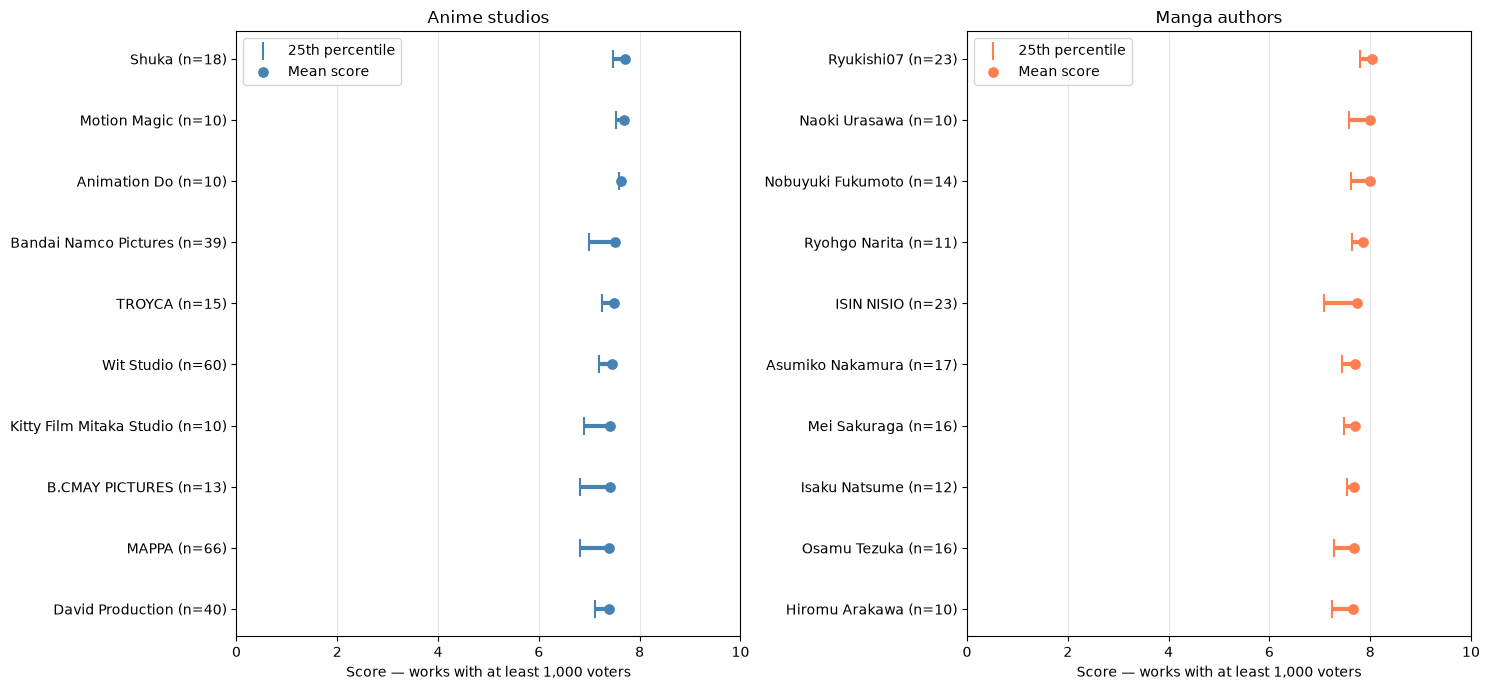

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(15, 7))

for ax, summary, title, color in [
    (axes[0], studio_scores, "Anime studios", "steelblue"),
    (axes[1], author_scores, "Manga authors", "coral")
]:
    top = (
        summary.loc[summary["eligible_works"].ge(10)]
        .nlargest(10, "mean_score")
        .sort_values("mean_score")
    )

    labels = (
        top["creator"].tolist()
        if "creator" in top.columns
        else top.index.tolist()
    )

    positions = range(len(top))

    ax.hlines(
        positions,
        top["lower_quartile"],
        top["mean_score"],
        color=color,
        linewidth=3
    )

    ax.scatter(
        top["lower_quartile"], positions,
        color=color, marker="|", s=150,
        label="25th percentile"
    )

    ax.scatter(
        top["mean_score"], positions,
        color=color, s=45, label="Mean score"
    )

    ax.set_yticks(list(positions))
    ax.set_yticklabels([
        f"{label} (n={count})"
        for label, count in zip(labels, top["eligible_works"])
    ])

    ax.set_xlim(0, 10)
    ax.set_title(title)
    ax.set_xlabel("Score — works with at least 1,000 voters")
    ax.grid(axis="x", alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()

In [34]:
for name, data, summary, group_column in [
    ("Anime studios", anime_production, studio_scores, "creator"),
    ("Manga authors", manga_production, author_scores, "creator_id")
]:
    small_catalog = summary.index[
        summary["works"].between(1, 3)
    ]

    candidates = data.loc[
        data[group_column].isin(small_catalog)
        & data["score"].ge(8)
        & data["scored_by"].ge(1000)
    ]

    print(f"\n{name}: small recorded catalogs with highly rated works")

    display(
        candidates[
            ["creator", "title", "score", "scored_by",
             "members", "favorites"]
        ]
        .sort_values(
            ["members", "score"],
            ascending=[True, False]
        )
        .head(10)
    )


Anime studios: small recorded catalogs with highly rated works


,creator,title,score,scored_by,members,favorites
2520,Nippon Ramayana Film Co.,Ramayana: The Legend of Prince Rama,8.33,4941,9670,173
2275,K-Factory,Ginga Eiyuu Densetsu Gaiden (1999),8.06,7291,19643,24
2079,K-Factory,Ginga Eiyuu Densetsu Gaiden,8.12,8654,23345,66
748,BUG FILMS,Zom 100: Zombie ni Naru made ni Shitai 100 no ...,8.29,45994,285625,1665
437,K-Factory,Ginga Eiyuu Densetsu,9.02,76123,307951,15766



Manga authors: small recorded catalogs with highly rated works


,creator,title,score,scored_by,members,favorites
2307,Inori.,Watashi no Oshi wa Akuyaku Reijou.: Revolution,8.27,1046,3104,204
2307,Hanagata,Watashi no Oshi wa Akuyaku Reijou.: Revolution,8.27,1046,3104,204
2176,Makiburo,Akuyaku Reijou no Naka no Hito: Danzai sareta ...,8.22,1129,3397,70
1566,Ringo Manda,Complex,8.17,1686,3853,142
1310,Chae-eun,Daytime Star,8.26,1963,4179,124
1310,Godago,Daytime Star,8.26,1963,4179,124
1946,J. Soori,Semantic Error,8.01,1390,4238,140
1946,Angy,Semantic Error,8.01,1390,4238,140
1877,Shiho Inada,Ghost Hunt: Akumu no Sumu Ie,8.03,1443,4304,51
1627,Namsu,Romance 101,8.07,1684,4353,171


### Problem 10 — Scores by production

We compare anime studios and manga authors using works
with at least 1,000 voters. The main rankings require
at least 10 eligible works per studio or author.
Each eligible work receives equal weight.

Shuka leads the eligible anime studios with a mean score
of 7.71 across 18 works. However, its minimum score is 5.65,
showing that a high average can hide variation.
Motion Magic and Animation Do have minimum eligible
scores of 7.33, suggesting consistently positive reception
within their selected catalogs.

Ryukishi07 leads the eligible manga authors with a mean
score of 8.03 across 23 works, followed by Naoki Urasawa
at approximately 8.00 across 10 works.
These figures cover only 35.38% and 47.62% of their
recorded catalogs, respectively.

We cannot establish that any creator is universally liked.
The dataset contains aggregate work scores, not agreement
among individual voters. The voting threshold also
excludes many less popular or recent works.

Small recorded catalogs can contain highly rated titles.
For example, Ramayana: The Legend of Prince Rama has
a score of 8.33 from 4,941 voters and 9,670 members.
This makes it a candidate for investigating strong
reception within a relatively small platform audience,
but does not establish cult-classic status.

K-Factory's listed titles belong to the same named
franchise. This suggests concentration in its recorded
credits, but does not establish the studio's complete
production history or exclusive specialization.

The selected leading manga authors have higher mean
scores than the selected leading anime studios.
This is descriptive: authors and studios have different
roles, and their catalogs and audiences differ.
The result does not establish that one medium is better.

Collaborative works are credited to each listed studio
or author. Manga author roles, such as story and art,
are combined here. Related franchise entries may also
share audiences, so works are not necessarily independent.

The plots connect the lower quartile to the mean score;
these lines are not confidence intervals.
Missing credits, catalog coverage and the chosen thresholds
limit the conclusions.

### Problem 11. Storytelling
No, not the plots (although you could use the plot synopsis as a meaningful feature). Try to tell a coherent story based on the data. You could use what you've found so far, or try exploring something new. But make your story _worthy_.

Formulate one story based on the data. Keep the principles of analytical graphs in mind; and with the help of some text and plots, tell the story you found interesting. Make it look at least somewhat finished. Support your storytelling with evidence. You should also see that pure evidence without some storytelling is useless :).

### Higher ratings, smaller audiences: manga and anime on MyAnimeList

Does a higher rating imply a larger audience?
Comparing anime and manga reveals why these measures
should be considered separately.

We compare median scores among rated works, median
membership counts across all works with recorded values,
and the percentage of works with a recorded score.

,median_score,median_members,rated_percent
medium,,,
Anime,6.42,1085.0,64.24
Manga,6.91,190.0,38.00


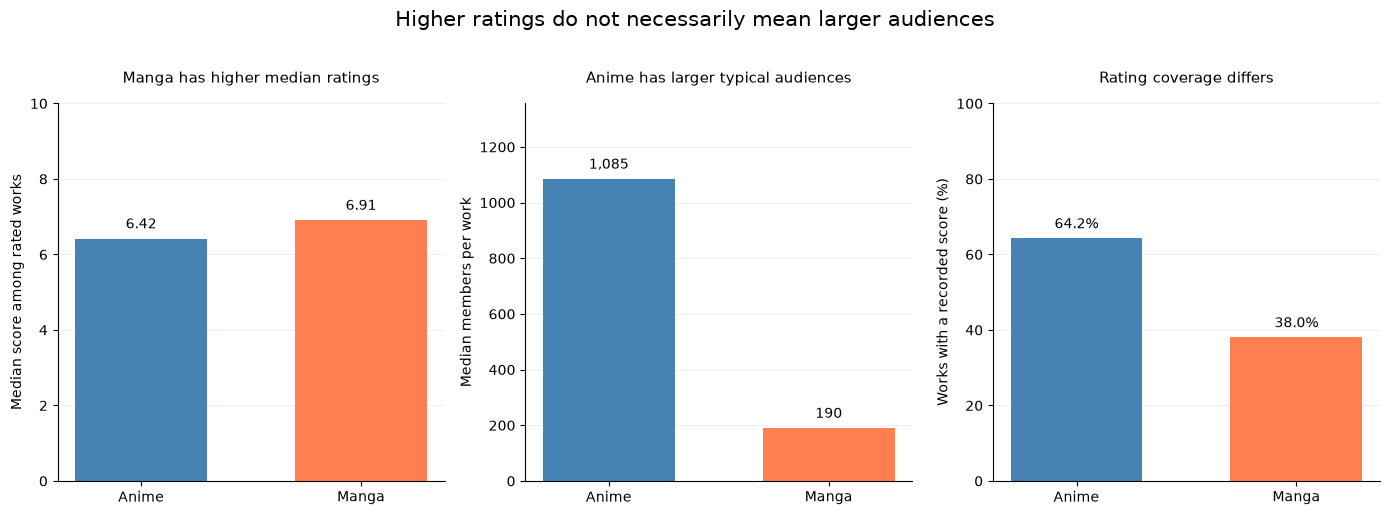

In [35]:
story_rows = []

for medium, df in [("Anime", anime), ("Manga", manga)]:
    story_rows.append({
        "medium": medium,
        "median_score": df["score"].median(),
        "median_members": df["members"].median(),
        "rated_percent": 100 * df["score"].notna().mean()
    })

story_summary = (
    pd.DataFrame(story_rows)
    .set_index("medium")
    .reindex(["Anime", "Manga"])
)

display(story_summary.round(2))

fig, axes = plt.subplots(1, 3, figsize=(14, 5))

colors = ["steelblue", "coral"]

for ax, metric, title, ylabel, limit, number_format in [
    (
        axes[0], "median_score",
        "Manga has higher median ratings",
        "Median score among rated works",
        (0, 10), "{:.2f}"
    ),
    (
        axes[1], "median_members",
        "Anime has larger typical audiences",
        "Median members per work",
        None, "{:,.0f}"
    ),
    (
        axes[2], "rated_percent",
        "Rating coverage differs",
        "Works with a recorded score (%)",
        (0, 100), "{:.1f}%"
    )
]:
    values = story_summary[metric]

    bars = ax.bar(
        story_summary.index,
        values,
        color=colors,
        width=0.6
    )

    ax.bar_label(
        bars,
        labels=[number_format.format(value) for value in values],
        padding=5
    )

    ax.set_title(title, fontsize=11, pad=15)
    ax.set_ylabel(ylabel)
    ax.grid(axis="y", alpha=0.2)
    ax.set_axisbelow(True)

    if limit is not None:
        ax.set_ylim(*limit)
    else:
        ax.set_ylim(0, values.max() * 1.25)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

fig.suptitle(
    "Higher ratings do not necessarily mean larger audiences",
    fontsize=15,
    y=1.02
)

plt.tight_layout()
plt.show()

### The story behind the comparison

Rated manga has a higher median score than rated anime:
6.91 compared with 6.42. Yet anime has a much larger
median membership count: 1,085 compared with 190.
Thus, higher ratings at the medium level do not necessarily
coincide with larger typical platform audiences.

However, the score comparison covers different proportions
of the catalogs. Scores are recorded for approximately
64.24% of anime but only 38.00% of manga.
The median manga score therefore describes a smaller
share of its catalog. We cannot assume that unrated works
would receive similar scores.

This does not contradict the positive associations between
score and popularity found within each medium in Problem 4.
A relationship within a group need not explain differences
between groups.

Catalog composition, platform participation and which works
receive ratings may contribute to the contrast.
These are possible explanations, not established causes.

Members counts indicate inclusion in platform users' lists,
not verified viewing or reading. Scores describe reception
among participating raters, not objective quality.
The score and membership summaries also use different
sets of available records.

The central finding is that reception has several dimensions:
manga leads on median recorded score, while anime leads
on median membership. Unequal rating coverage limits
how broadly we can interpret that comparison.

### * Problem 12. Making a better plot
Try to take one plot - I'm almost convinced this will be from Problem 11. Iterate over it to make it look better: show more info in one image but donb't overwhelm the reader, make it easier to read and understand. Use `matplotlib` but try to push it to the limit of what it can do.

I suggest that you keep your plot non-animated and non-interactive for simplicity. Ideally, show all intermediate actions, results, and how you decided to improve the plot.

### Improving the storytelling figure

The original figure in Problem 11 communicates three
different measures, but repeats category labels and
does not show how many works support the score comparison.

Iteration 1 uses horizontal bars, consistent colors and
direct value labels to make the comparisons easier to scan.

Iteration 2 adds rated-work counts and displays rating
coverage as a rated/unrated composition. It also states
which records contribute to each metric.

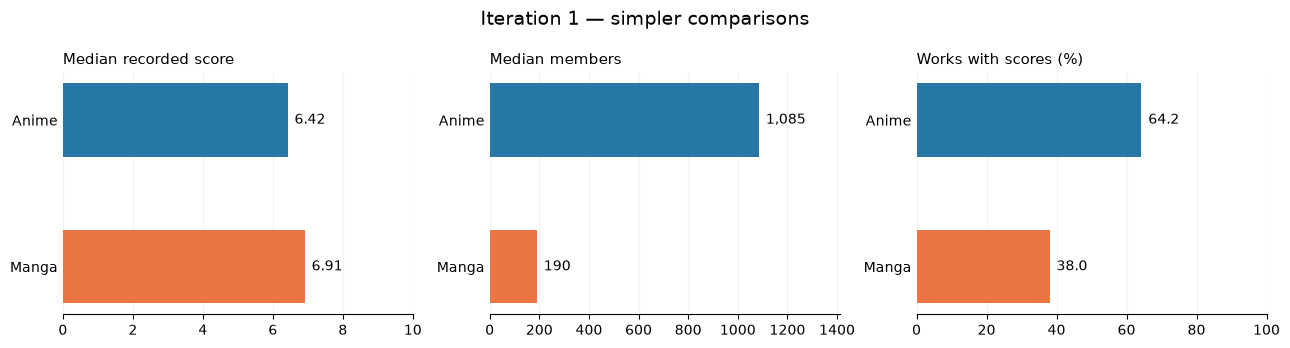

In [36]:
media = ["Anime", "Manga"]
story_colors = ["#2878A5", "#E87542"]

fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))

for ax, metric, title, xmax, fmt in [
    (axes[0], "median_score", "Median recorded score", 10, ".2f"),
    (axes[1], "median_members", "Median members", 
     story_summary["median_members"].max() * 1.3, ",.0f"),
    (axes[2], "rated_percent", "Works with scores (%)", 100, ".1f")
]:
    values = story_summary.loc[media, metric]

    bars = ax.barh(media, values, color=story_colors, height=0.5)

    ax.bar_label(
        bars,
        labels=[format(value, fmt) for value in values],
        padding=5
    )

    ax.set_xlim(0, xmax)
    ax.invert_yaxis()
    ax.set_title(title, loc="left", fontsize=11)
    ax.grid(axis="x", alpha=0.15)
    ax.set_axisbelow(True)

    for spine in ["top", "right", "left"]:
        ax.spines[spine].set_visible(False)

    ax.tick_params(axis="y", length=0)

fig.suptitle("Iteration 1 — simpler comparisons", fontsize=14)
plt.tight_layout()
plt.show()

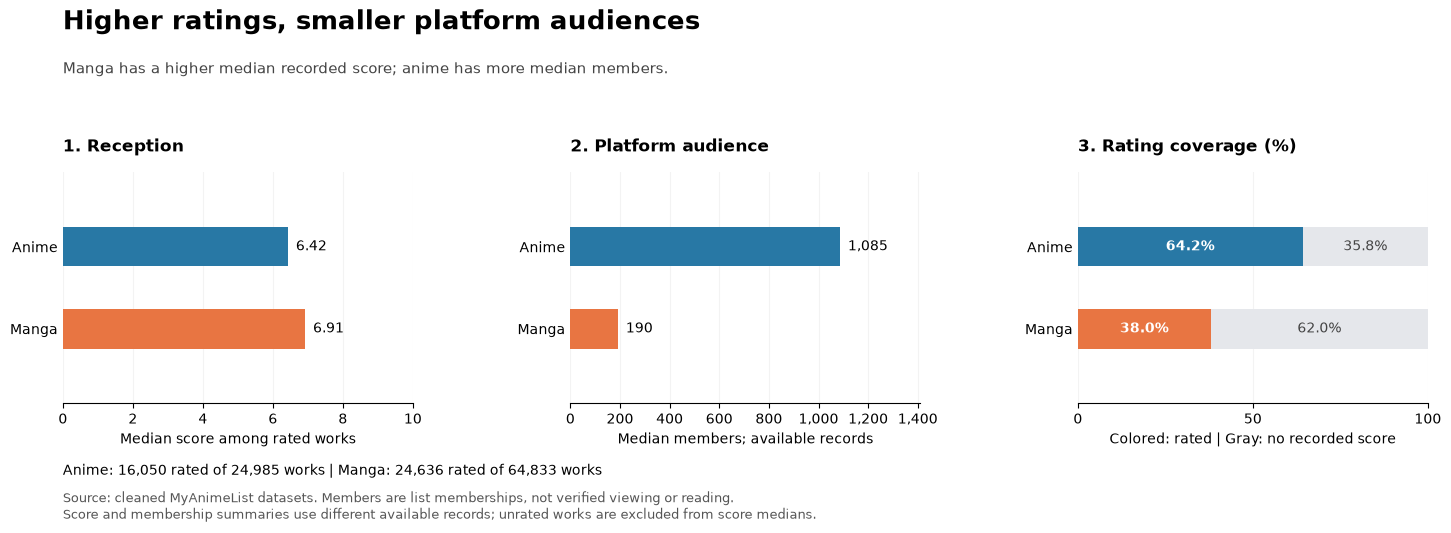

In [37]:
from matplotlib.ticker import StrMethodFormatter

story_counts = pd.DataFrame({
    medium: {
        "total": len(df),
        "rated": df["score"].notna().sum()
    }
    for medium, df in [("Anime", anime), ("Manga", manga)]
}).T

fig, axes = plt.subplots(1, 3, figsize=(15, 5.5))

fig.subplots_adjust(
    left=0.07, right=0.98,
    top=0.69, bottom=0.27, wspace=0.45
)

fig.text(
    0.07, 0.95,
    "Higher ratings, smaller platform audiences",
    fontsize=19, weight="bold"
)
fig.text(
    0.07, 0.87,
    "Manga has a higher median recorded score; "
    "anime has more median members.",
    fontsize=11, color="#444444"
)

# Panel 1: scores
values = story_summary.loc[media, "median_score"]

bars = axes[0].barh(
    media, values, color=story_colors, height=0.48
)
axes[0].bar_label(bars, fmt="%.2f", padding=6)
axes[0].set_xlim(0, 10)
axes[0].set_xlabel("Median score among rated works")
axes[0].set_title("1. Reception", loc="left", weight="bold", pad=15)

# Panel 2: membership
values = story_summary.loc[media, "median_members"]

bars = axes[1].barh(
    media, values, color=story_colors, height=0.48
)
axes[1].bar_label(
    bars,
    labels=[f"{value:,.0f}" for value in values],
    padding=6
)
axes[1].set_xlim(0, values.max() * 1.3)
axes[1].xaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
axes[1].set_xlabel("Median members; available records")
axes[1].set_title("2. Platform audience", loc="left", weight="bold", pad=15)

# Panel 3: rated and unrated shares
rated = story_summary.loc[media, "rated_percent"]

axes[2].barh(
    media, rated, color=story_colors, height=0.48
)
axes[2].barh(
    media, 100 - rated,
    left=rated, color="#E5E7EB", height=0.48
)

for position, medium in enumerate(media):
    percent = rated.loc[medium]

    axes[2].text(
        percent / 2, position,
        f"{percent:.1f}%",
        ha="center", va="center",
        color="white", weight="bold"
    )

    axes[2].text(
        percent + (100 - percent) / 2, position,
        f"{100 - percent:.1f}%",
        ha="center", va="center",
        color="#444444"
    )

axes[2].set_xlim(0, 100)
axes[2].set_xticks([0, 50, 100])
axes[2].set_xlabel("Colored: rated | Gray: no recorded score")
axes[2].set_title("3. Rating coverage (%)", loc="left", weight="bold", pad=15)

for ax in axes:
    ax.invert_yaxis()
    ax.grid(axis="x", alpha=0.15)
    ax.set_axisbelow(True)
    ax.tick_params(axis="y", length=0)
    ax.margins(y=0.45)

    for spine in ["top", "right", "left"]:
        ax.spines[spine].set_visible(False)

counts_note = " | ".join(
    f"{medium}: {int(story_counts.loc[medium, 'rated']):,} rated "
    f"of {int(story_counts.loc[medium, 'total']):,} works"
    for medium in media
)

fig.text(0.07, 0.14, counts_note, fontsize=10)

fig.text(
    0.07, 0.06,
    "Source: cleaned MyAnimeList datasets. Members are list memberships, "
    "not verified viewing or reading.\n"
    "Score and membership summaries use different available records; "
    "unrated works are excluded from score medians.",
    fontsize=9, color="#555555"
)

plt.show()

### Design decisions

- Preserved the original figure and both iterations.
- Used consistent colors and category order across panels.
- Kept separate axes for metrics with different units.
- Retained zero baselines for all bars.
- Added direct labels to reduce reliance on axis reading.
- Showed rated and unrated shares together.
- Added the number of rated works and catalog totals.
- Included data definitions and limitations within the figure.

The final version adds context without changing the
underlying measurements or conclusions.

### * Problem 13. Continue cleaning and exploring
Perform what other cleaning operations / transformations / EDA you might see fit. Save the final results as one or more tables. Try using **dvc** to keep track of versions and what you did to them; and to possibly be able to revert if something goes wrong.

You can do as little, or as much as you'd like. Have fun! :)

In [38]:
quality_rows = []

for medium, df, id_column in [
    ("Anime", anime, "anime_id"),
    ("Manga", manga, "manga_id")
]:
    quality_rows.append({
        "medium": medium,
        "rows": len(df),
        "missing_ids": df[id_column].isna().sum(),
        "duplicate_ids": df[id_column].duplicated().sum(),
        "scores_outside_1_10": (
            df["score"].notna()
            & ~df["score"].between(1, 10)
        ).sum(),
        "negative_members": df["members"].lt(0).sum(),
        "negative_favorites": df["favorites"].lt(0).sum(),
        "negative_voters": df["scored_by"].lt(0).sum(),
        "score_without_positive_votes": (
            df["score"].notna()
            & ~df["scored_by"].gt(0)
        ).sum()
    })

quality_report = pd.DataFrame(quality_rows)
display(quality_report)

,medium,rows,missing_ids,duplicate_ids,scores_outside_1_10,negative_members,negative_favorites,negative_voters,score_without_positive_votes
0,Anime,24985,0,0,0,0,0,0,0
1,Manga,64833,0,0,0,0,0,0,0


In [43]:
output_dir = Path("eda_results")
output_dir.mkdir(parents=True, exist_ok=True)

# Save copies with explicit metadata-coverage flags
for medium, df in [("anime", anime), ("manga", manga)]:
    final = df.copy()

    for feature in ["genres", "themes", "demographics"]:
        final[f"has_{feature}"] = (
            final[feature].apply(parse_genres).map(bool)
        )

    final.to_csv(
        output_dir / f"{medium}_eda.csv",
        index=False,
        encoding="utf-8"
    )

# Tidy genre tables
anime_genres.to_csv(
    output_dir / "anime_genres_tidy.csv", index=False
)
manga_genres.to_csv(
    output_dir / "manga_genres_tidy.csv", index=False
)

summaries = {
    "quality_report": quality_report,
    "label_coverage": coverage,
    "label_missingness": missingness,
    "story_summary": story_summary.reset_index(),
    "anime_genre_summary": anime_genre_summary.reset_index(),
    "manga_genre_summary": manga_genre_summary.reset_index(),
    "studio_scores": studio_scores.reset_index(),
    "author_scores": author_scores.reset_index()
}

for medium, table in time_summaries.items():
    summaries[f"{medium.lower()}_by_decade"] = table.reset_index()

for (medium, feature), table in label_tables.items():
    summaries[f"{medium.lower()}_{feature}"] = table.reset_index()

for filename, table in summaries.items():
    table.to_csv(
        output_dir / f"{filename}.csv",
        index=False,
        encoding="utf-8"
    )

print("Saved to:", output_dir.resolve())

for path in sorted(output_dir.glob("*.csv")):
    print(path.name)

Saved to: D:\Data Science\02.Data Visualization and EDA Exercise\eda_results
anime_by_decade.csv
anime_demographics.csv
anime_eda.csv
anime_genre_summary.csv
anime_genres_tidy.csv
anime_themes.csv
author_scores.csv
label_coverage.csv
label_missingness.csv
manga_by_decade.csv
manga_demographics.csv
manga_eda.csv
manga_genre_summary.csv
manga_genres_tidy.csv
manga_themes.csv
quality_report.csv
story_summary.csv
studio_scores.csv


### Problem 13 — Final checks and exported results

We checked identifier completeness and uniqueness,
score ranges, negative counts, and scores without
positive voter counts. These checks flag potential
problems rather than silently correcting them.

The final work-level tables retain missing scores and
metadata. Boolean flags distinguish works with recorded
genres, themes and demographics from those without labels.
An absent label is not interpreted as an absent property.

We exported the final work-level tables, tidy genre tables,
and summaries of time periods, labels, production credits
and storytelling metrics to the eda_results directory.
Original input CSV files remain unchanged.

CSV files do not preserve all pandas data types.
Date columns should be parsed again when loading,
and list-valued columns require explicit parsing.

The notebook records the transformations and analytical
choices needed to reproduce these outputs.
DVC was not configured in this exercise.